# Demanda de Inventario de Grupo Bimbo con SVM (Máquinas de Soporte Vectorial) + MLflow

Nombres: Christian Naula y Kevin Mendez

En la práctica anterior predijimos la demanda con un **LSTM**. Ahora hacemos lo mismo con una **SVM**. Para que los dos modelos se puedan comparar, todo lo demás se queda igual:

* Las mismas series **Agencia × Producto** (las que tienen las 7 semanas completas).
* Las mismas variables, incluidas las temporales (media móvil y cambio %).
* La misma división: entrenamiento hasta la semana 7, **validación en la semana 8** y **prueba en la semana 9**.
* La misma métrica: **RMSE en unidades reales** y el mismo modelo ingenuo de referencia.

**Novedad de esta versión: MLflow.** Cada modelo que entrenamos (cada prueba de cada experimento, incluidas **todas** las combinaciones del GridSearch) queda registrado con sus parámetros, sus métricas y sus gráficas. Al final MLflow busca el mejor resultado entre todas las pruebas y ese modelo se guarda en el **Model Registry**.

# Mapa del cuaderno

| Parte | Qué se hace | Dataset usado |
|---|---|---|
| 0. MLflow | Qué es, cómo se instala y cómo se organiza | — |
| 1. Carga de datos | Leer `train.csv`, `producto_tabla` y `cliente_tabla` | Completo (74M filas) |
| 2. Secuencias de tiempo | Series Agencia × Producto, variables temporales y ventanas | Completo (agregado) |
| 3. Modelo SVM y finetuning | Embudo: Exp1 ventana y variables → Exp2 comparación rápida de kernels → Exp3 finetuning con GridSearch → modelo final. Cada experimento es un *run* de MLflow con sus pruebas dentro | Completo (agregado) |
| 4. Funciones de predicción | Predecir con el modelo cargado desde el Model Registry | Completo (agregado) |

# Parte 0. ¿Qué es MLflow y cómo lo usamos aquí?

Cuando hacemos finetuning entrenamos muchos modelos. Sin MLflow, los resultados viven en variables del cuaderno y en `print`: si volvemos a correr una celda, el resultado anterior **se pierde**. MLflow es una "bitácora" que guarda cada entrenamiento en disco para poder compararlos después.

## Conceptos

| Concepto | Qué es | En este cuaderno |
|---|---|---|
| **Experiment** | Una carpeta que agrupa entrenamientos del mismo problema | `Bimbo_SVM_Demanda` |
| **Run** | Un entrenamiento (o un grupo de entrenamientos) | Cada experimento (Exp1, Exp2, Exp3) es un **run padre** |
| **Run hijo (nested)** | Un run dentro de otro | Cada prueba (cada kernel, cada C, cada gamma) es un **run hijo** |
| **Params** | Lo que **elegimos** antes de entrenar | ventana, variables, kernel, C, gamma, epsilon |
| **Metrics** | Lo que **medimos** después de entrenar | RMSE validación, MAE, segundos, mejora vs ingenuo |
| **Artifacts** | Archivos que guardamos | Gráficas (.png), tablas (.csv), el modelo entrenado |
| **Model Registry** | El "catálogo" de modelos oficiales, con versiones | `SVM_Demanda_Bimbo`, con el alias `champion` para el mejor |

## Estructura que se va a crear

```
Experiment: Bimbo_SVM_Demanda
├── Exp1_ventana_y_variables      (¿con qué datos? kernel linear; run padre: tabla + gráfica)
│   ├── exp1_v1_originales        (run hijo: params, métricas, gráfica real vs predicho, modelo)
│   ├── exp1_v1_temporales
│   ├── exp1_v3_originales
│   └── exp1_v3_temporales
├── Exp2_kernels                  (¿qué kernel? pasada rápida sin ajustar; run padre: tabla + gráfica)
│   ├── exp2_SVM_linear ... exp2_Regresion_Lineal   (6 hijos)
├── Exp3_grid_search              (finetuning de linear y rbf; run padre: cv_results_ completo + heatmap)
│   ├── exp3_linear_C0.1          (un run hijo por CADA combinación, no solo la mejor)
│   ├── ...                       (12 en total)
│   └── exp3_rbf_C10_gscale
└── Modelo_final                  (entrenado con la mejor configuración; RMSE semana 9;
                                   registrado en el Model Registry como SVM_Demanda_Bimbo@champion)
```

## Lo que mencionó el profesor sobre GridSearch

`GridSearchCV` por defecto se queda con el **mejor** modelo (`best_estimator_`), y si solo registramos ese, perdemos la información de las demás combinaciones. Pero `GridSearchCV` sí guarda los resultados de **todas** en `cv_results_`. Aquí recorremos `cv_results_` y creamos **un run hijo por cada combinación**. Así en MLflow se puede ver (y graficar) cómo cambia el RMSE con C y gamma, no solo el ganador.

## Instalación (una sola vez)

En la terminal (o Anaconda Prompt):

```
pip install mlflow
```

O ejecuta la celda de abajo. Después de instalar, **reinicia el kernel** del cuaderno.

## Cómo ver los resultados (la interfaz web)

1. Abre una terminal **en la misma carpeta donde está este cuaderno**.
2. Ejecuta:
   ```
   mlflow ui --backend-store-uri sqlite:///mlflow.db
   ```
3. Abre en el navegador: **http://127.0.0.1:5000**
4. Deja esa terminal abierta mientras uses la interfaz (para cerrarla: `Ctrl + C`).

Los datos quedan en dos cosas dentro de la carpeta del cuaderno: el archivo `mlflow.db` (parámetros y métricas) y la carpeta `mlruns/` (gráficas, tablas y modelos).

In [1]:
# Ejecutar UNA sola vez para instalar MLflow (luego reiniciar el kernel). Si ya esta instalado, no hace nada.
#%pip install mlflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Parte 1. Carga de datos

**Dataset usado: completo (74M filas).**

In [1]:
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np
import copy
import os
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [2]:
dtypes = { #bajar la memoria de los datos para mejorar la lectura de datos 
    'Semana': 'int8',
    'Agencia_ID': 'int16',
    'Canal_ID': 'int8',
    'Ruta_SAK': 'int32',
    'Cliente_ID': 'int32',
    'Producto_ID': 'int32',
    'Venta_uni_hoy': 'int32',
    'Venta_hoy': 'float32',
    'Dev_uni_proxima': 'int32',
    'Dev_proxima': 'float32',
    'Demanda_uni_equil': 'int32'
}

productos = pd.read_csv("../data/raw/producto_tabla.csv") 
clientes = pd.read_csv("../data/raw/cliente_tabla.csv")

df = pd.read_csv("../data/raw/train.csv", dtype=dtypes) #nrows=3_000_000) #May change | skiprows=range(1, 50_000_001), , nrows=6_000_000

In [3]:
#Presentar: Cuantas valores hay en cada semana antes de cambiarlo:
listita = df['Semana'].unique()
for i in range(2,11):
    print( f" Semana {i} tiene: {(df['Semana'] == i).sum()} registros")

 Semana 2 tiene: 0 registros
 Semana 3 tiene: 11165207 registros
 Semana 4 tiene: 11009593 registros
 Semana 5 tiene: 10615397 registros
 Semana 6 tiene: 10191837 registros
 Semana 7 tiene: 10382849 registros
 Semana 8 tiene: 10406868 registros
 Semana 9 tiene: 10408713 registros
 Semana 10 tiene: 0 registros


In [4]:
df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
0,3,1110,7,3301,15766,1212,3,25.139999,0,0.0,3
1,3,1110,7,3301,15766,1216,4,33.520000,0,0.0,4
2,3,1110,7,3301,15766,1238,4,39.320000,0,0.0,4
3,3,1110,7,3301,15766,1240,4,33.520000,0,0.0,4
4,3,1110,7,3301,15766,1242,3,22.920000,0,0.0,3


In [5]:
trainCliente = df['Cliente_ID'].nunique()
trainProducto = df['Producto_ID'].nunique()
print(f"Numero de valores unicos Cliente_ID en train: {trainCliente}") 
print(f"Numero de valores unicos Producto_ID en train: {trainProducto}")
print(df.shape[0])

Numero de valores unicos Cliente_ID en train: 880604
Numero de valores unicos Producto_ID en train: 1799
74180464


In [6]:
print(df.columns)
#Variables categoricas:
varCatNominal = ['Semana', 'Agencia_ID', 'Canal_ID', 'Ruta_SAK']
# Cliente_ID y Producto_ID tambien son categoricas nominales, 
#pero por la cantidad de datos no se procesaran, se usaran otros metodos.

#Variables Numericas:
varNumericas = ["Venta_uni_hoy", "Venta_hoy","Dev_uni_proxima", "Dev_proxima", "Demanda_uni_equil"]

Index(['Semana', 'Agencia_ID', 'Canal_ID', 'Ruta_SAK', 'Cliente_ID',
       'Producto_ID', 'Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima',
       'Dev_proxima', 'Demanda_uni_equil'],
      dtype='object')


# Parte 2. Secuencias de tiempo

**Dataset usado: completo, agregado por Agencia × Producto × Semana.**

Igual que con el LSTM: sumamos la demanda de todos los clientes de una agencia para cada producto y semana. Una serie es, por ejemplo, *"el Pan Blanco de la agencia 1110 de la semana 3 a la 9"*. Los 74M de filas se convierten en unas 54 mil series y nos quedamos solo con las que tienen las 7 semanas completas.

In [7]:
# Variables que sumamos por semana (una fila por Agencia x Producto x Semana)
cols = ['Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima', 'Dev_proxima', 'Demanda_uni_equil']
semanas = list(range(3, 10))

agg = df.groupby(['Agencia_ID', 'Producto_ID', 'Semana'])[cols].sum().astype('float64')

agg.head()

Venta_uni_hoy   Venta_hoy  Dev_uni_proxima  \
Agencia_ID Producto_ID Semana                                               
1110       73          3                18.0  383.760010              0.0   
                       4                24.0  511.679993              0.0   
                       5                13.0  277.160004              2.0   
                       6                 6.0  127.919998              0.0   
                       7                36.0  767.519958              0.0   

                               Dev_proxima  Demanda_uni_equil  
Agencia_ID Producto_ID Semana                                  
1110       73          3          0.000000               18.0  
                       4          0.000000               24.0  
                       5         42.639999               12.0  
                       6          0.000000                6.0  
                       7          0.000000               36.0

In [8]:
# Una fila por serie (Agencia, Producto) y una columna por (variable, semana)
wide = agg.unstack('Semana')
wide = wide.dropna()  # nos quedamos con las series que tienen las 7 semanas
wide.head()

Venta_uni_hoy                                       \
Semana                             3      4       5       6      7      8   
Agencia_ID Producto_ID                                                      
1110       73                   18.0   24.0    13.0     6.0   36.0   36.0   
           108                 656.0  584.0   552.0   268.0  504.0  745.0   
           145                 849.0  749.0  1127.0  1347.0  943.0  594.0   
           202                 666.0  647.0   644.0   607.0  566.0  644.0   
           205                 128.0  109.0   105.0   136.0  132.0  123.0   

                                  Venta_hoy                              ...  \
Semana                      9             3             4             5  ...   
Agencia_ID Producto_ID                                                   ...   
1110       73            36.0    383.760010    511.679993    277.160004  ...   
           108          688.0   4198.399902   3737.600098   3532.800049  ...   
           145          688.0  16767.750000  14792.750000  22258.250000  ...   
           202          676.0  27272.699219  26494.650391  26371.800781  ...   
           205          141.0   4203.520020   3579.560059   3448.199951  ...   

                       Dev_proxima                  Demanda_uni_equil         \
Semana                           7          8     9                 3      4   
Agencia_ID Producto_ID                                                         
1110       73                 0.00   0.000000   0.0              18.0   24.0   
           108                0.00   0.000000   0.0             656.0  584.0   
           145              177.75   0.000000  79.0             849.0  748.0   
           202                0.00  81.900002   0.0             666.0  647.0   
           205                0.00   0.000000   0.0             128.0  109.0   

                                                             
Semana                       5       6      7      8      9  
Agencia_ID Producto_ID                                       
1110       73             12.0     6.0   36.0   36.0   36.0  
           108           552.0   268.0  504.0  745.0  688.0  
           145          1126.0  1347.0  938.0  594.0  685.0  
           202           644.0   607.0  566.0  642.0  676.0  
           205           105.0   136.0  132.0  123.0  141.0  

[5 rows x 35 columns]

In [9]:

wide = wide.reindex(columns=pd.MultiIndex.from_product([cols, semanas]))
print(f"Series con las 7 semanas: {wide.shape[0]}")

Series con las 7 semanas: 53714


In [10]:
# Asi se ve la demanda de algunas series: una fila por (Agencia, Producto) y una columna por semana
wide['Demanda_uni_equil'].head()
#MultiIndex o índice jerárquico.

3      4       5       6      7      8      9
Agencia_ID Producto_ID                                                   
1110       73            18.0   24.0    12.0     6.0   36.0   36.0   36.0
           108          656.0  584.0   552.0   268.0  504.0  745.0  688.0
           145          849.0  748.0  1126.0  1347.0  938.0  594.0  685.0
           202          666.0  647.0   644.0   607.0  566.0  642.0  676.0
           205          128.0  109.0   105.0   136.0  132.0  123.0  141.0

In [27]:
wide.head()

Venta_uni_hoy                                       \
                                   3      4       5       6      7      8   
Agencia_ID Producto_ID                                                      
1110       73                   18.0   24.0    13.0     6.0   36.0   36.0   
           108                 656.0  584.0   552.0   268.0  504.0  745.0   
           145                 849.0  749.0  1127.0  1347.0  943.0  594.0   
           202                 666.0  647.0   644.0   607.0  566.0  644.0   
           205                 128.0  109.0   105.0   136.0  132.0  123.0   

                                  Venta_hoy                              ...  \
                            9             3             4             5  ...   
Agencia_ID Producto_ID                                                   ...   
1110       73            36.0    383.760010    511.679993    277.160004  ...   
           108          688.0   4198.399902   3737.600098   3532.800049  ...   
           145          688.0  16767.750000  14792.750000  22258.250000  ...   
           202          676.0  27272.699219  26494.650391  26371.800781  ...   
           205          141.0   4203.520020   3579.560059   3448.199951  ...   

                       Dev_proxima                  Demanda_uni_equil         \
                                 7          8     9                 3      4   
Agencia_ID Producto_ID                                                         
1110       73                 0.00   0.000000   0.0              18.0   24.0   
           108                0.00   0.000000   0.0             656.0  584.0   
           145              177.75   0.000000  79.0             849.0  748.0   
           202                0.00  81.900002   0.0             666.0  647.0   
           205                0.00   0.000000   0.0             128.0  109.0   

                                                             
                             5       6      7      8      9  
Agencia_ID Producto_ID                                       
1110       73             12.0     6.0   36.0   36.0   36.0  
           108           552.0   268.0  504.0  745.0  688.0  
           145          1126.0  1347.0  938.0  594.0  685.0  
           202           644.0   607.0  566.0  642.0  676.0  
           205           105.0   136.0  132.0  123.0  141.0  

[5 rows x 35 columns]

## 2.1 Variables temporales (Feature Engineering para el modelo)

Son las mismas de la práctica del LSTM. El dataset no tiene fechas, solo el número de semana, así que las variables temporales salen del historial de cada serie:

| Variable | Qué mide | Ejemplo (demanda 100, 120, 90) |
|---|---|---|
| Semana anterior | La demanda de la última semana | 90 |
| Media móvil (3 semanas) | El promedio de las últimas 3 semanas | (100+120+90)/3 = 103.3 |
| Cambio % | Cuánto subió o bajó respecto a la semana anterior | (90−120)/120 = −25% |

In [11]:
# Demanda en unidades: matriz de (series, 7 semanas)
demanda = wide['Demanda_uni_equil'].values

# Media movil: promedio de la semana actual y las 2 anteriores
# (en las primeras semanas se promedia lo que haya: la semana 3 sola, luego 3 y 4, ...)
media_movil = np.zeros_like(demanda)
for t in range(demanda.shape[1]):
    inicio = max(0, t - 2)
    media_movil[:, t] = demanda[:, inicio:t + 1].mean(axis=1)

# Cambio %: (semana actual - semana anterior) / semana anterior
# La semana 3 no tiene semana anterior, asi que su cambio queda en 0
cambio_pct = np.zeros_like(demanda)
for t in range(1, demanda.shape[1]):
    anterior = demanda[:, t - 1]
    actual = demanda[:, t]
    # Si la semana anterior fue 0 no se puede dividir: dejamos el cambio en 0
    cambio_pct[:, t] = np.where(anterior > 0, (actual - anterior) / np.maximum(anterior, 1), 0)

# Recortamos los valores extremos (ej. pasar de 1 a 500 unidades = +49,900%)
# para que no dominen la normalizacion: el cambio queda entre -100% y +300%
cambio_pct = np.clip(cambio_pct, -1, 3)

print(f"Media movil: {media_movil.shape} | Cambio %: {cambio_pct.shape}")

Media movil: (53714, 7) | Cambio %: (53714, 7)


In [12]:
# Ejemplo con una serie: como quedan las variables temporales semana a semana
ejemplo = pd.DataFrame({
    'Demanda': demanda[0],
    'Media movil (3 sem)': media_movil[0].round(1),
    'Cambio %': (cambio_pct[0] * 100).round(1)
}, index=[f'Semana {s}' for s in semanas])

print(f"Serie: Agencia {wide.index[0][0]}, Producto {wide.index[0][1]}")
ejemplo

Serie: Agencia 1110, Producto 73


,Demanda,Media movil (3 sem),Cambio %
Semana 3,18.0,18.0,0.0
Semana 4,24.0,21.0,33.3
Semana 5,12.0,18.0,-50.0
Semana 6,6.0,14.0,-50.0
Semana 7,36.0,18.0,300.0
Semana 8,36.0,26.0,0.0
Semana 9,36.0,36.0,0.0


## 2.2 Normalización

Juntamos las 5 columnas originales con las 2 variables temporales y normalizamos todo entre 0 y 1. El *scaler* se ajusta solo con las semanas 3 a 8: la semana 9 es la prueba final y el modelo no debe conocerla de antemano.

Para la SVM normalizar es **todavía más importante** que para el LSTM: la SVM mide distancias entre ejemplos, así que si una variable está en pesos (miles) y otra en porcentaje, la de pesos dominaría todo.

In [13]:
from sklearn.preprocessing import MinMaxScaler
from pandas import DataFrame

DEM = 4    # posicion de Demanda_uni_equil dentro de cols #ultima posicion
N_SEM = 3  # semanas que mira el modelo

# Forma: (series, 7 semanas, 5 variables)
datos_valores = wide.values

datos = datos_valores.reshape(len(wide), len(cols), len(semanas)).transpose(0, 2, 1)

print(DataFrame(datos_valores[:2,:]))

      0      1      2      3      4      5      6            7            8   \
0   18.0   24.0   13.0    6.0   36.0   36.0   36.0   383.760010   511.679993   
1  656.0  584.0  552.0  268.0  504.0  745.0  688.0  4198.399902  3737.600098   

            9   ...   25   26   27     28     29     30     31     32     33  \
0   277.160004  ...  0.0  0.0  0.0   18.0   24.0   12.0    6.0   36.0   36.0   
1  3532.800049  ...  0.0  0.0  0.0  656.0  584.0  552.0  268.0  504.0  745.0   

      34  
0   36.0  
1  688.0  

[2 rows x 35 columns]


In [14]:
print(datos_valores[:2,:].astype('int'))

[[  18   24   13    6   36   36   36  383  511  277  127  767  767  767
     0    0    2    0    0    0    0    0    0   42    0    0    0    0
    18   24   12    6   36   36   36]
 [ 656  584  552  268  504  745  688 4198 3737 3532 1715 3225 4768 4403
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
   656  584  552  268  504  745  688]]


In [15]:
print(datos_valores[:2,:].reshape(2,5,7).astype('int'))

[[[  18   24   13    6   36   36   36]
  [ 383  511  277  127  767  767  767]
  [   0    0    2    0    0    0    0]
  [   0    0   42    0    0    0    0]
  [  18   24   12    6   36   36   36]]

 [[ 656  584  552  268  504  745  688]
  [4198 3737 3532 1715 3225 4768 4403]
  [   0    0    0    0    0    0    0]
  [   0    0    0    0    0    0    0]
  [ 656  584  552  268  504  745  688]]]


In [16]:
print(datos_valores[:2,:].reshape(2,5,7).transpose(0,2,1).astype('int'))

[[[  18  383    0    0   18]
  [  24  511    0    0   24]
  [  13  277    2   42   12]
  [   6  127    0    0    6]
  [  36  767    0    0   36]
  [  36  767    0    0   36]
  [  36  767    0    0   36]]

 [[ 656 4198    0    0  656]
  [ 584 3737    0    0  584]
  [ 552 3532    0    0  552]
  [ 268 1715    0    0  268]
  [ 504 3225    0    0  504]
  [ 745 4768    0    0  745]
  [ 688 4403    0    0  688]]]


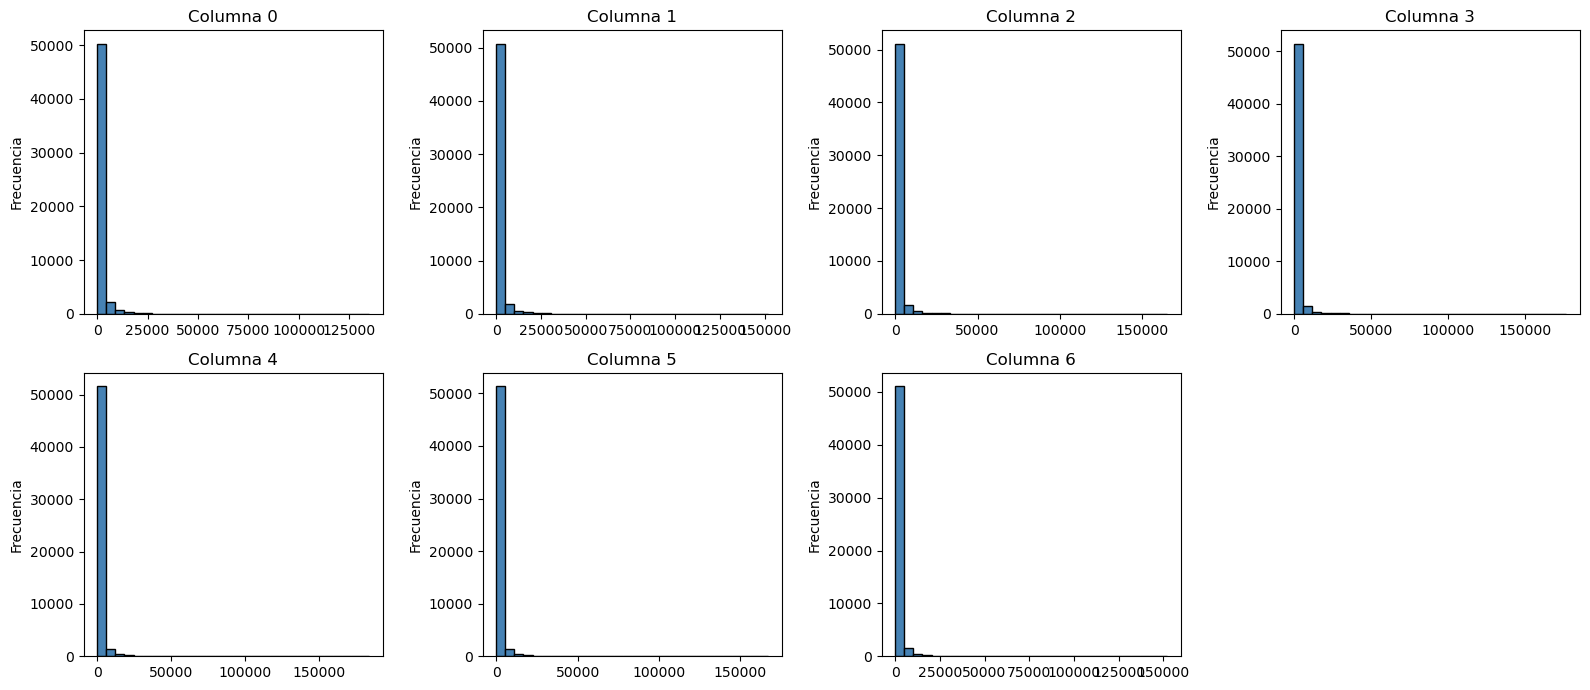

In [46]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 7))
axes = axes.ravel()  # Aplana la cuadrícula de ejes para iterar fácil

for i in range(7):
    axes[i].hist(media_movil[:, i], bins=30, color='steelblue', edgecolor='black')
    axes[i].set_title(f'Columna {i}')
    axes[i].set_ylabel('Frecuencia')

axes[7].axis('off')  # Oculta el octavo espacio vacío
plt.tight_layout()
plt.show()

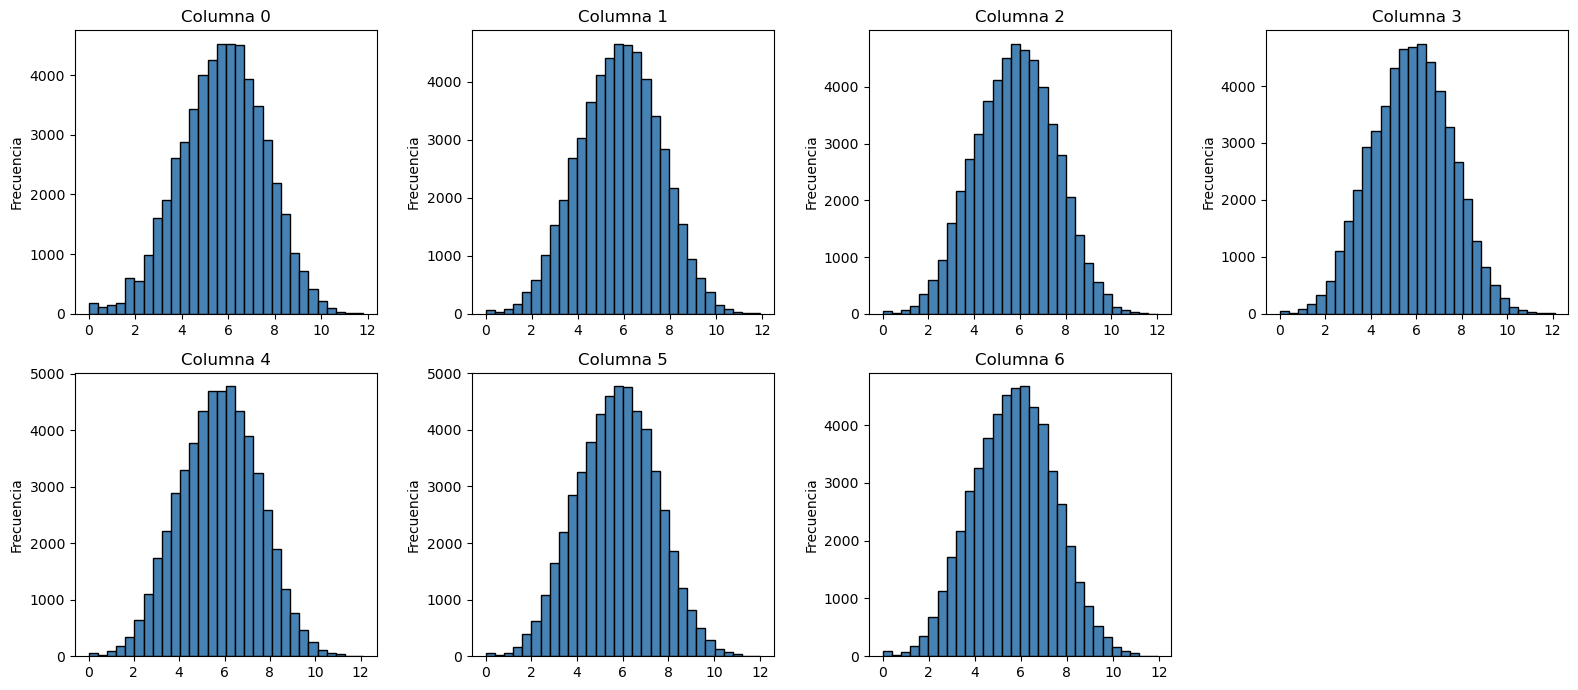

In [17]:
media_movil2 = media_movil.copy()
cambioss =np.log1p(media_movil2)

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 7))
axes = axes.ravel()  # Aplana la cuadrícula de ejes para iterar fácil

for i in range(7):
    axes[i].hist(cambioss[:, i], bins=30, color='steelblue', edgecolor='black')
    axes[i].set_title(f'Columna {i}')
    axes[i].set_ylabel('Frecuencia')

axes[7].axis('off')  # Oculta el octavo espacio vacío
plt.tight_layout()
plt.show()

In [20]:
datos.shape

(53714, 7, 7)

In [18]:
# log1p: la demanda tiene cola muy larga; asi la normalizacion no se aplasta
datos = np.log1p(datos)

# Agregamos las 2 variables temporales -> forma (series, 7 semanas, 7 variables)
# La media movil esta en unidades, asi que tambien lleva log1p. El cambio % ya es un numero pequeno
datos = np.concatenate([datos,
                        np.log1p(media_movil)[:, :, np.newaxis],
                        cambio_pct[:, :, np.newaxis]], axis=2)
nombres_variables = cols + ['Media_movil', 'Cambio_pct']
print(f"Forma de los datos: {datos.shape}  ->  variables: {nombres_variables}")

# Normalizamos (0-1) ajustando solo con las semanas de entrenamiento (3 a 8)
scaler = MinMaxScaler(feature_range=(0, 1))
#reshape no elimina columnas ni semanas. Reorganiza los datos. Temporalmente combierte a array 2d
scaler.fit(datos[:, :6, :].reshape(-1, datos.shape[2]))
datos_esc = scaler.transform(datos.reshape(-1, datos.shape[2])).reshape(datos.shape)

Forma de los datos: (53714, 7, 7)  ->  variables: ['Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima', 'Dev_proxima', 'Demanda_uni_equil', 'Media_movil', 'Cambio_pct']


In [31]:
datos[:2,:6,:]

array([[[ 2.94443898,  5.95261979,  0.        ,  0.        ,
          2.94443898,  2.94443898,  0.        ],
        [ 3.21887582,  6.23965185,  0.        ,  0.        ,
          3.21887582,  3.09104245,  0.33333333],
        [ 2.63905733,  5.6281965 ,  1.09861229,  3.77597415,
          2.56494936,  2.94443898, -0.5       ],
        [ 1.94591015,  4.85919204,  0.        ,  0.        ,
          1.94591015,  2.7080502 , -0.5       ],
        [ 3.61091791,  6.64446653,  0.        ,  0.        ,
          3.61091791,  2.94443898,  3.        ],
        [ 3.61091791,  6.64446653,  0.        ,  0.        ,
          3.61091791,  3.29583687,  0.        ]],

       [[ 6.48768402,  8.34269691,  0.        ,  0.        ,
          6.48768402,  6.48768402,  0.        ],
        [ 6.37161185,  8.22646651,  0.        ,  0.        ,
          6.37161185,  6.43133108, -0.1097561 ],
        [ 6.315358  ,  8.17012907,  0.        ,  0.        ,
          6.315358  ,  6.39414801, -0.05479452],
        

In [29]:
datos[:2, :6, :].reshape(-1, datos.shape[2])

array([[ 2.94443898,  5.95261979,  0.        ,  0.        ,  2.94443898,
         2.94443898,  0.        ],
       [ 3.21887582,  6.23965185,  0.        ,  0.        ,  3.21887582,
         3.09104245,  0.33333333],
       [ 2.63905733,  5.6281965 ,  1.09861229,  3.77597415,  2.56494936,
         2.94443898, -0.5       ],
       [ 1.94591015,  4.85919204,  0.        ,  0.        ,  1.94591015,
         2.7080502 , -0.5       ],
       [ 3.61091791,  6.64446653,  0.        ,  0.        ,  3.61091791,
         2.94443898,  3.        ],
       [ 3.61091791,  6.64446653,  0.        ,  0.        ,  3.61091791,
         3.29583687,  0.        ],
       [ 6.48768402,  8.34269691,  0.        ,  0.        ,  6.48768402,
         6.48768402,  0.        ],
       [ 6.37161185,  8.22646651,  0.        ,  0.        ,  6.37161185,
         6.43133108, -0.1097561 ],
       [ 6.315358  ,  8.17012907,  0.        ,  0.        ,  6.315358  ,
         6.39414801, -0.05479452],
       [ 5.59471138,  7.4478

In [19]:
datosPrint = wide.values.reshape(len(wide), len(cols), len(semanas))
wide.head()

Venta_uni_hoy                                       \
                                   3      4       5       6      7      8   
Agencia_ID Producto_ID                                                      
1110       73                   18.0   24.0    13.0     6.0   36.0   36.0   
           108                 656.0  584.0   552.0   268.0  504.0  745.0   
           145                 849.0  749.0  1127.0  1347.0  943.0  594.0   
           202                 666.0  647.0   644.0   607.0  566.0  644.0   
           205                 128.0  109.0   105.0   136.0  132.0  123.0   

                                  Venta_hoy                              ...  \
                            9             3             4             5  ...   
Agencia_ID Producto_ID                                                   ...   
1110       73            36.0    383.760010    511.679993    277.160004  ...   
           108          688.0   4198.399902   3737.600098   3532.800049  ...   
           145          688.0  16767.750000  14792.750000  22258.250000  ...   
           202          676.0  27272.699219  26494.650391  26371.800781  ...   
           205          141.0   4203.520020   3579.560059   3448.199951  ...   

                       Dev_proxima                  Demanda_uni_equil         \
                                 7          8     9                 3      4   
Agencia_ID Producto_ID                                                         
1110       73                 0.00   0.000000   0.0              18.0   24.0   
           108                0.00   0.000000   0.0             656.0  584.0   
           145              177.75   0.000000  79.0             849.0  748.0   
           202                0.00  81.900002   0.0             666.0  647.0   
           205                0.00   0.000000   0.0             128.0  109.0   

                                                             
                             5       6      7      8      9  
Agencia_ID Producto_ID                                       
1110       73             12.0     6.0   36.0   36.0   36.0  
           108           552.0   268.0  504.0  745.0  688.0  
           145          1126.0  1347.0  938.0  594.0  685.0  
           202           644.0   607.0  566.0  642.0  676.0  
           205           105.0   136.0  132.0  123.0  141.0  

[5 rows x 35 columns]

## 2.3 Ventanas de tiempo y división en entrenamiento, validación y prueba

Cada ejemplo es: **entrada = las N semanas anteriores**, **salida = la demanda de la semana siguiente**. La división es la misma que con el LSTM:

| Ventana | Entrenamiento (semanas objetivo) | Validación | Prueba |
|---|---|---|---|
| 1 semana | 4, 5, 6, 7 | 8 | 9 |
| 3 semanas | 6, 7 | 8 | 9 |

**Lo único que cambia: la forma de la entrada.** El LSTM recibe una secuencia en 3D y la SVM una tabla en 2D, porque no entiende el orden del tiempo: solo ve una fila de números. Por eso "aplanamos" las semanas de la ventana en una sola fila:

| Modelo | Forma de X (ventana 3, 7 variables) | Qué ve |
|---|---|---|
| LSTM | (ejemplos, 3, 7) | 3 pasos de tiempo con 7 variables cada uno |
| SVM | (ejemplos, 21) | 21 columnas: las 7 variables de la semana 1, luego las de la semana 2 y luego las de la semana 3 |

In [33]:
variables = list(range(datos_esc.shape[2])) 
print(variables)
datos.shape

[0, 1, 2, 3, 4, 5, 6]


(53714, 7, 7)

In [34]:
#datos ya normalizados, semanas que se usaran (lista con los numeros de la semana, por eso se 
#resta -3 para obtener index, n-sem para sabes hacia cuanto se mira atras
#Variable re asignadas para recordar
DEM = 4    # posicion de Demanda_uni_equil dentro de cols #ultima posicion
N_SEM = 3  # semanas que mira el modelo
def ventanas(datos_esc, semanas_objetivo, n_sem=N_SEM, variables=None):
    if variables is None:
        variables = list(range(datos_esc.shape[2]))  # todas las variables
    X = np.concatenate([ datos_esc[:, (s-3)-n_sem:(s-3), :][:, :, variables] for s in semanas_objetivo ])
    y = np.concatenate([datos_esc[:, s-3, DEM] for s in semanas_objetivo])
    return X, y

# NUEVO: la SVM necesita una tabla 2D, asi que aplanamos (ejemplos, semanas, variables) -> (ejemplos, semanas x variables)
def ventanas_svm(datos_esc, semanas_objetivo, n_sem=N_SEM, variables=None):
    X, y = ventanas(datos_esc, semanas_objetivo, n_sem, variables)
    return X.reshape(len(X), -1), y

# Semanas objetivo de entrenamiento segun el tamano de la ventana
# (la primera semana que se puede predecir es 3 + n_sem; la 8 queda para validacion)
def semanas_entrenamiento(n_sem):
    return list(range(3 + n_sem, 8))
# 6,7
SEMANA_VAL = 8
SEMANA_TEST = 9

VARS_ORIGINALES = [0, 1, 2, 3, 4]               # las 5 columnas de cols
VARS_CON_TEMPORALES = [0, 1, 2, 3, 4, 5, 6]     # + Media_movil y Cambio_pct

for n in [1, 3]:
    X_3d, _ = ventanas(datos_esc, semanas_entrenamiento(n), n)
    X_2d, _ = ventanas_svm(datos_esc, semanas_entrenamiento(n), n)
    print(f"Ventana de {n}: entrena con semanas {semanas_entrenamiento(n)} -> "
          f"LSTM {X_3d.shape} | SVM {X_2d.shape}")

Ventana de 1: entrena con semanas [4, 5, 6, 7] -> LSTM (214856, 1, 7) | SVM (214856, 7)
Ventana de 3: entrena con semanas [6, 7] -> LSTM (107428, 3, 7) | SVM (107428, 21)


In [35]:
# Comprobacion: la fila aplanada de la SVM tiene exactamente los mismos numeros que la secuencia del LSTM
X_3d, _ = ventanas(datos_esc, [SEMANA_VAL], 3)
X_2d, _ = ventanas_svm(datos_esc, [SEMANA_VAL], 3)
print("Misma informacion en 3D y en 2D:", np.array_equal(X_3d[0].ravel(), X_2d[0]))

Misma informacion en 3D y en 2D: True


In [40]:
datos_esc[:2, :, :]

array([[[0.24198812, 0.42680226, 0.        , 0.        , 0.24203882,
         0.24288698, 0.25      ],
        [0.26454265, 0.44738243, 0.        , 0.        , 0.26459808,
         0.25498031, 0.33333333],
        [0.21689039, 0.40354114, 0.11958775, 0.32822578, 0.21084401,
         0.24288698, 0.125     ],
        [0.15992423, 0.34840359, 0.        , 0.        , 0.15995774,
         0.22338725, 0.125     ],
        [0.29676255, 0.4764076 , 0.        , 0.        , 0.29682473,
         0.24288698, 1.        ],
        [0.29676255, 0.4764076 , 0.        , 0.        , 0.29682473,
         0.27187382, 0.25      ],
        [0.29676255, 0.4764076 , 0.        , 0.        , 0.29682473,
         0.29786487, 0.25      ]],

       [[0.53318898, 0.59817055, 0.        , 0.        , 0.53330071,
         0.53516952, 0.25      ],
        [0.52364962, 0.58983685, 0.        , 0.        , 0.52375934,
         0.53052096, 0.22256098],
        [0.51902641, 0.58579746, 0.        , 0.        , 0.51913516,
  

In [41]:
X_3d[:2, :,:]

array([[[0.21689039, 0.40354114, 0.11958775, 0.32822578, 0.21084401,
         0.24288698, 0.125     ],
        [0.15992423, 0.34840359, 0.        , 0.        , 0.15995774,
         0.22338725, 0.125     ],
        [0.29676255, 0.4764076 , 0.        , 0.        , 0.29682473,
         0.24288698, 1.        ]],

       [[0.51902641, 0.58579746, 0.        , 0.        , 0.51913516,
         0.52745372, 0.23630137],
        [0.45980021, 0.53401139, 0.        , 0.        , 0.45989656,
         0.50736366, 0.12137681],
        [0.51156406, 0.57927672, 0.        , 0.        , 0.51167125,
         0.50253477, 0.47014925]]])

In [43]:
X_2d[:2, :]

array([[0.21689039, 0.40354114, 0.11958775, 0.32822578, 0.21084401,
        0.24288698, 0.125     , 0.15992423, 0.34840359, 0.        ,
        0.        , 0.15995774, 0.22338725, 0.125     , 0.29676255,
        0.4764076 , 0.        , 0.        , 0.29682473, 0.24288698,
        1.        ],
       [0.51902641, 0.58579746, 0.        , 0.        , 0.51913516,
        0.52745372, 0.23630137, 0.45980021, 0.53401139, 0.        ,
        0.        , 0.45989656, 0.50736366, 0.12137681, 0.51156406,
        0.57927672, 0.        , 0.        , 0.51167125, 0.50253477,
        0.47014925]])

# Parte 3. Modelo SVM y finetuning

**Dataset usado: completo, agregado.**

Como queremos predecir una **cantidad** (unidades) y no una clase, usamos **SVR** (*Support Vector Regression*), la versión de la SVM para regresión. En la práctica del crédito usamos `SVC` porque la salida era bueno/malo.

**¿Cómo funciona la SVR?** Busca una función que pase cerca de los puntos, pero ignora los errores pequeños: todo lo que cae dentro de un "tubo" de ancho **epsilon** alrededor de la predicción no se castiga. Solo los puntos que quedan fuera del tubo (los *vectores de soporte*) definen el modelo.

**Parámetros principales** (los mismos que vimos en clase):
* **kernel:** la forma de la función. `linear` es una recta (hiperplano); `rbf` permite relaciones no lineales.
* **C:** cuánto se castigan los errores fuera del tubo. C alto = se ajusta más al entrenamiento (riesgo de overfitting).
* **gamma:** solo para `rbf`. Qué tan lejos llega la influencia de cada punto. Gamma alto = curvas más "nerviosas".
* **epsilon:** el ancho del tubo. Lo dejamos en 0.01 porque la demanda está escalada entre 0 y 1 (el valor por defecto, 0.1, sería un 10% de todo el rango: demasiado grande).

**Métrica: RMSE** en unidades reales, igual que con el LSTM. **Modelo de referencia (ingenuo):** predecir que la próxima semana se demanda lo mismo que la semana anterior. Si la SVM no le gana a esto, no sirve.

In [16]:
from math import sqrt
from time import time
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

# Regresamos de la escala 0-1 a unidades reales
def a_unidades(y_esc):
    y_log = y_esc * (scaler.data_max_[DEM] - scaler.data_min_[DEM]) + scaler.data_min_[DEM]
    return np.maximum(np.expm1(y_log), 0)

# RMSE en unidades reales (no en la escala 0-1)
def rmse_unidades(y_esc_real, y_esc_pred):
    return sqrt(mean_squared_error(a_unidades(y_esc_real), a_unidades(y_esc_pred)))

# Modelo ingenuo en validacion: la demanda de la semana 8 = la de la semana 7
val_X, val_y = ventanas(datos_esc, [SEMANA_VAL], 1)
rmse_ingenuo_val = rmse_unidades(val_y, val_X[:, -1, DEM])
print(f"RMSE ingenuo en validacion (semana 8): {rmse_ingenuo_val:.2f}")

RMSE ingenuo en validacion (semana 8): 690.28


## 3.0 Configurar MLflow

* `set_tracking_uri("sqlite:///mlflow.db")`: dónde se guarda todo. Usamos una base de datos SQLite (un archivo) porque el **Model Registry necesita una base de datos**; con la opción por defecto (carpeta de archivos) no se pueden registrar modelos.
* `set_experiment(...)`: crea el experimento si no existe (o usa el que ya existe).
* `EJECUCION`: una etiqueta con la fecha y hora. Si corres el cuaderno varias veces, todas las corridas se acumulan en MLflow (eso es bueno, nada se pierde); la etiqueta sirve para que el "mejor modelo" se busque solo entre las pruebas de **esta** ejecución.

Además definimos funciones de ayuda para que cada prueba se registre igual:
* `params_modelo(...)`: arma el diccionario de parámetros (lo que elegimos).
* `log_prueba(...)`: crea el **run hijo** y registra parámetros, métricas, la gráfica real vs. predicho y el modelo.

In [17]:
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient
from datetime import datetime
from sklearn.metrics import mean_absolute_error
import joblib, json

mlflow.set_tracking_uri("sqlite:///mlflow.db")   # base de datos local (archivo mlflow.db en esta carpeta)
NOMBRE_EXPERIMENTO = "Bimbo_SVM_Demanda"
NOMBRE_MODELO_REGISTRO = "SVM_Demanda_Bimbo"     # nombre en el Model Registry
mlflow.set_experiment(NOMBRE_EXPERIMENTO)
client = MlflowClient()

# Etiqueta de esta ejecucion del cuaderno (para no mezclar con corridas de otros dias)
EJECUCION = datetime.now().strftime("%Y%m%d_%H%M%S")
print(f"MLflow {mlflow.__version__} | experimento: {NOMBRE_EXPERIMENTO} | ejecucion: {EJECUCION}")


def params_modelo(n_sem, variables, modelo_tipo='SVR', kernel='rbf', C=1.0, gamma='scale',
                  epsilon=0.01, degree=3, coef0=0.0, n_muestra=None):
    # Todo lo que ELEGIMOS antes de entrenar. MLflow guarda los params como texto.
    p = {'ventana': n_sem,
         'variables': ','.join(nombres_variables[v] for v in variables),
         'n_variables': len(variables),
         'modelo_tipo': modelo_tipo,
         'n_muestra': n_muestra if n_muestra is not None else N_MUESTRA}
    if modelo_tipo == 'SVR':
        p.update({'kernel': kernel, 'C': C, 'gamma': gamma, 'epsilon': epsilon})
        if kernel == 'poly':
            p.update({'degree': degree, 'coef0': coef0})
    return p


def grafica_real_vs_pred(y_real_u, y_pred_u, titulo):
    # Dispersion real vs predicho en unidades (escala log para que se vean las series chicas y grandes)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(y_real_u + 1, y_pred_u + 1, s=3, alpha=0.3)
    lim = [1, max(y_real_u.max(), y_pred_u.max()) + 1]
    ax.plot(lim, lim, 'r--', label='Prediccion perfecta')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('Real (unidades + 1)'); ax.set_ylabel('Predicho (unidades + 1)')
    ax.set_title(titulo, fontsize=9)
    ax.legend()
    fig.tight_layout()
    return fig


def log_prueba(nombre_run, experimento, params, model, val_X, val_y, segundos,
               pred=None, guardar_modelo=True):
    # Crea un RUN HIJO dentro del run padre que este abierto y registra todo de una prueba
    with mlflow.start_run(run_name=nombre_run, nested=True):
        mlflow.set_tags({'experimento': experimento, 'tipo': 'prueba', 'ejecucion': EJECUCION})
        mlflow.log_params(params)

        if pred is None:
            pred = model.predict(val_X)
        y_real_u, y_pred_u = a_unidades(val_y), a_unidades(pred)
        rmse_val = sqrt(mean_squared_error(y_real_u, y_pred_u))

        # Metricas: lo que MEDIMOS despues de entrenar
        mlflow.log_metric('rmse_val', rmse_val)
        mlflow.log_metric('mae_val', mean_absolute_error(y_real_u, y_pred_u))
        mlflow.log_metric('mejora_vs_ingenuo_pct', (rmse_ingenuo_val - rmse_val) / rmse_ingenuo_val * 100)
        mlflow.log_metric('segundos_entrenamiento', segundos)
        if hasattr(model, 'support_'):
            mlflow.log_metric('n_vectores_soporte', len(model.support_))

        # Grafica de esta prueba (artifact)
        fig = grafica_real_vs_pred(y_real_u, y_pred_u, f'{nombre_run}\nRMSE validacion = {rmse_val:.1f}')
        mlflow.log_figure(fig, 'graficas/real_vs_predicho.png')
        plt.close(fig)

        # El modelo entrenado (artifact). Asi se puede recuperar cualquier prueba, no solo la ultima
        if guardar_modelo:
            mlflow.sklearn.log_model(model, name='modelo', input_example=val_X[:5])
    return rmse_val

2026/11/19 02:08:24 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 02:08:24 INFO mlflow.store.db.utils: Updating database tables
2026/11/19 02:08:26 INFO mlflow.tracking.fluent: Experiment with name 'Bimbo_SVM_Demanda' does not exist. Creating a new experiment.


MLflow 3.18.0 | experimento: Bimbo_SVM_Demanda | ejecucion: 20261119_020826


## 3.1 Diseño del modelo

**Diferencia importante con el LSTM: el tamaño del entrenamiento.** El LSTM aprende por lotes (`batch_size=512`), así que puede usar todos los ejemplos. La SVR no: compara los ejemplos entre sí de dos en dos, así que el tiempo crece con el **cuadrado** de los datos. Con ventana de 1 hay unos 216 mil ejemplos de entrenamiento (54 mil series × 4 semanas) y la SVR tardaría horas.

Por eso **entrenamos con una muestra al azar de ejemplos** (`N_MUESTRA`). Ojo, no es lo mismo que la muestra del 3% de la práctica anterior:
* Aquí se eligen **ventanas ya armadas**, así que cada ejemplo conserva su historia completa (las series no se rompen).
* La muestra es **solo para entrenar**. La validación (semana 8) y la prueba (semana 9) se hacen con **todas** las series.
* Las dos ventanas usan el mismo tamaño de muestra, así la comparación es justa.

In [18]:
os.makedirs('figuras', exist_ok=True)  # aqui se guardan las graficas para las diapositivas

N_MUESTRA = 20_000  # ejemplos para entrenar en los experimentos (subirlo mejora un poco, pero tarda mas)

# Muestra al azar de ejemplos de entrenamiento (siempre la misma gracias a la semilla)
def muestra(X, y, n, semilla=42):
    if len(X) <= n:
        return X, y  # si hay menos ejemplos que n, se usan todos
    rng = np.random.default_rng(semilla)
    filas = rng.choice(len(X), size=n, replace=False)
    return X[filas], y[filas]

def crear_modelo(kernel='rbf', C=1.0, gamma='scale', epsilon=0.01):
    # SVR = SVM para regresion (predice un numero, no una clase)
    # cache_size: memoria (MB) para guardar calculos del kernel; acelera el entrenamiento
    return SVR(kernel=kernel, C=C, gamma=gamma, epsilon=epsilon, cache_size=1000)

def entrenar(n_sem, variables, kernel='rbf', C=1.0, gamma='scale', epsilon=0.01, n_muestra=N_MUESTRA):
    # Entrena con una muestra de las semanas de entrenamiento y mide el RMSE en validacion (semana 8)
    # CAMBIO para MLflow: tambien devuelve val_X, val_y y la prediccion, para registrarlos en log_prueba
    train_X, train_y = ventanas_svm(datos_esc, semanas_entrenamiento(n_sem), n_sem, variables)
    train_X, train_y = muestra(train_X, train_y, n_muestra)
    val_X, val_y = ventanas_svm(datos_esc, [SEMANA_VAL], n_sem, variables)

    inicio = time()
    model = crear_modelo(kernel, C, gamma, epsilon)
    model.fit(train_X, train_y)
    segundos = time() - inicio

    pred = model.predict(val_X)
    rmse_val = rmse_unidades(val_y, pred)
    return model, rmse_val, segundos, val_X, val_y, pred

## 3.2 Experimento 1: ventana de 1 vs. 3 semanas, con y sin variables temporales

El mismo experimento que hicimos con el LSTM: entrenamos 4 SVR iguales cambiando solo dos cosas: cuántas semanas mira y si recibe las variables temporales. Se comparan con el RMSE de validación (semana 8).

**¿Por qué kernel `linear` (C=1) y no `rbf`?** Aquí queremos comparar **los datos**, no el modelo, así que necesitamos un modelo que no "estorbe":
* `linear` no tiene gamma y casi no depende de C, así que funciona bien sin ajustarlo.
* `rbf` con valores por defecto usa `gamma='scale'`, que se calcula como `1 / (número de columnas × varianza)`. Con ventana 1 y 5 variables el modelo ve 5 columnas; con ventana 3 y temporales, 21. Es decir, al cambiar las variables **también cambiaría gamma sin querer**, y no sabríamos si la diferencia viene de los datos o de gamma.

**En MLflow:** se abre un run padre `Exp1_ventana_y_variables` y cada una de las 4 pruebas es un run hijo con sus parámetros, métricas, gráfica y modelo. Al final el run padre guarda la tabla resumen.

In [19]:
opciones_variables = [('Originales (5)', VARS_ORIGINALES),
                      ('Con temporales (7)', VARS_CON_TEMPORALES)]

resultados_exp1 = []
with mlflow.start_run(run_name='Exp1_ventana_y_variables') as run_padre:
    RUN_EXP1 = run_padre.info.run_id
    mlflow.set_tags({'experimento': 'exp1', 'tipo': 'experimento', 'ejecucion': EJECUCION})
    mlflow.log_params({'kernel': 'linear', 'C': 1.0, 'n_muestra': N_MUESTRA})
    mlflow.log_metric('rmse_ingenuo_val', rmse_ingenuo_val)

    for n_sem in [1, 3]:
        for nombre_vars, variables in opciones_variables:
            model, rmse_val, segundos, val_X, val_y, pred = entrenar(n_sem, variables, kernel='linear')
            etiqueta = 'originales' if variables == VARS_ORIGINALES else 'temporales'
            log_prueba(f'exp1_v{n_sem}_{etiqueta}', 'exp1', params_modelo(n_sem, variables, kernel='linear'),
                       model, val_X, val_y, segundos, pred)
            resultados_exp1.append({'Ventana': n_sem, 'Variables': nombre_vars,
                                    'Vectores de soporte': len(model.support_),
                                    'Segundos': round(segundos, 1), 'RMSE validacion': round(rmse_val, 2)})
            print(f"Ventana {n_sem} | {nombre_vars} | RMSE validacion: {rmse_val:.2f} | {segundos:.1f} s")

    tabla_exp1 = pd.DataFrame(resultados_exp1)
    mlflow.log_text(tabla_exp1.to_csv(index=False), 'tablas/exp1_resultados.csv')
    mlflow.log_metric('mejor_rmse_val', tabla_exp1['RMSE validacion'].min())

tabla_exp1

Ventana 1 | Originales (5) | RMSE validacion: 595.90 | 7.7 s


Ventana 1 | Con temporales (7) | RMSE validacion: 640.04 | 8.3 s


Ventana 3 | Originales (5) | RMSE validacion: 696.12 | 10.7 s


Ventana 3 | Con temporales (7) | RMSE validacion: 629.88 | 13.9 s


,Ventana,Variables,Vectores de soporte,Segundos,RMSE validacion
0,1,Originales (5),11891,7.7,595.90
1,1,Con temporales (7),11702,8.3,640.04
2,3,Originales (5),11561,10.7,696.12
3,3,Con temporales (7),11476,13.9,629.88


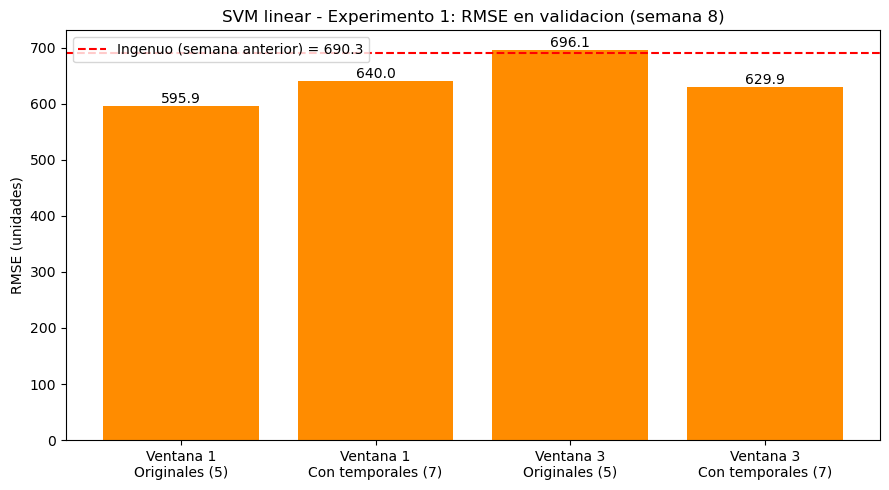

Mejor combinacion: ventana de 1 semana(s), variables Originales (5)


In [20]:
# Grafica del experimento 1 (para las diapositivas y para MLflow)
etiquetas = [f"Ventana {r['Ventana']}\n{r['Variables']}" for _, r in tabla_exp1.iterrows()]

fig = plt.figure(figsize=(9, 5))
plt.bar(etiquetas, tabla_exp1['RMSE validacion'], color='darkorange')
plt.axhline(rmse_ingenuo_val, color='red', linestyle='--', label=f'Ingenuo (semana anterior) = {rmse_ingenuo_val:.1f}')
for i, valor in enumerate(tabla_exp1['RMSE validacion']):
    plt.text(i, valor, f'{valor:.1f}', ha='center', va='bottom')
plt.title('SVM linear - Experimento 1: RMSE en validacion (semana 8)')
plt.ylabel('RMSE (unidades)')
plt.legend()
plt.tight_layout()
plt.savefig('figuras/svm_exp1_ventana_variables.png', dpi=150)
# El run padre ya se cerro: con el client guardamos la grafica en el usando su run_id
client.log_figure(RUN_EXP1, fig, 'graficas/exp1_ventana_variables.png')
plt.show()

# Nos quedamos con la combinacion de menor RMSE
mejor = tabla_exp1.loc[tabla_exp1['RMSE validacion'].idxmin()]
MEJOR_N_SEM = int(mejor['Ventana'])
MEJORES_VARS = VARS_ORIGINALES if mejor['Variables'] == 'Originales (5)' else VARS_CON_TEMPORALES
print(f"Mejor combinacion: ventana de {MEJOR_N_SEM} semana(s), variables {mejor['Variables']}")

## 3.3 Experimento 2: comparación rápida de kernels (sin ajustar)

Ya sabemos **con qué datos** entrenar (Experimento 1). Ahora la pregunta es **qué tipo de SVM** usar. Antes de gastar tiempo ajustando, hacemos una **primera pasada rápida**: probamos todos los kernels con los **valores por defecto** (C = 1, gamma = `scale`), con la misma ventana, las mismas variables y la misma muestra. Solo cambia el kernel. Sirve para **descartar** los que claramente no funcionan, y los que sobrevivan se ajustan a fondo en el Experimento 3.

| Kernel | Qué forma tiene la función | Idea simple |
|---|---|---|
| `linear` | Una recta / hiperplano | La demanda sube o baja en proporción a las entradas |
| `poly` (grado 2) | Una curva tipo parábola | Permite una curvatura suave |
| `poly` (grado 3) | Una curva más flexible | Más curvas, más riesgo de sobreajuste |
| `rbf` | Curvas "locales" alrededor de cada punto | Muy flexible; depende mucho de gamma |
| `sigmoid` | Forma de "S" (como una neurona) | Casi nunca funciona bien en regresión; lo dejamos para comparar |

Además agregamos **otro modelo** como referencia: una **Regresión Lineal** normal (sin SVM). Si una SVM no le gana a una regresión lineal, la complejidad extra no vale la pena.

**En MLflow:** run padre `Exp2_kernels` con 6 runs hijos (uno por modelo), cada uno con su modelo guardado y su gráfica real vs. predicho.

In [21]:
# Experimento 2: mismos datos para todos los modelos, solo cambia el kernel
train_X, train_y = ventanas_svm(datos_esc, semanas_entrenamiento(MEJOR_N_SEM), MEJOR_N_SEM, MEJORES_VARS)
train_X, train_y = muestra(train_X, train_y, N_MUESTRA)
val_X, val_y = ventanas_svm(datos_esc, [SEMANA_VAL], MEJOR_N_SEM, MEJORES_VARS)

# (nombre para la tabla, modelo, parametros para MLflow). Todos con C=1 y gamma='scale' (valores por defecto)
modelos_exp2 = [
    ('SVM linear',         SVR(kernel='linear', C=1, epsilon=0.01, cache_size=1000),
                           params_modelo(MEJOR_N_SEM, MEJORES_VARS, 'SVR', 'linear', 1.0)),
    ('SVM poly (grado 2)', SVR(kernel='poly', degree=2, coef0=1, C=1, epsilon=0.01, cache_size=1000),
                           params_modelo(MEJOR_N_SEM, MEJORES_VARS, 'SVR', 'poly', 1.0, degree=2, coef0=1.0)),
    ('SVM poly (grado 3)', SVR(kernel='poly', degree=3, coef0=1, C=1, epsilon=0.01, cache_size=1000),
                           params_modelo(MEJOR_N_SEM, MEJORES_VARS, 'SVR', 'poly', 1.0, degree=3, coef0=1.0)),
    ('SVM rbf',            SVR(kernel='rbf', C=1, epsilon=0.01, cache_size=1000),
                           params_modelo(MEJOR_N_SEM, MEJORES_VARS, 'SVR', 'rbf', 1.0)),
    ('SVM sigmoid',        SVR(kernel='sigmoid', C=1, epsilon=0.01, cache_size=1000),
                           params_modelo(MEJOR_N_SEM, MEJORES_VARS, 'SVR', 'sigmoid', 1.0)),
    ('Regresion Lineal',   LinearRegression(),  # otro modelo, sin SVM
                           params_modelo(MEJOR_N_SEM, MEJORES_VARS, 'LinearRegression')),
]
# coef0=1 en poly: sin esto el kernel polinomial solo multiplica las variables y aprende muy mal

resultados_exp2 = []
with mlflow.start_run(run_name='Exp2_kernels') as run_padre:
    RUN_EXP2 = run_padre.info.run_id
    mlflow.set_tags({'experimento': 'exp2', 'tipo': 'experimento', 'ejecucion': EJECUCION})
    mlflow.log_params({'ventana': MEJOR_N_SEM, 'n_variables': len(MEJORES_VARS), 'n_muestra': N_MUESTRA})
    mlflow.log_metric('rmse_ingenuo_val', rmse_ingenuo_val)

    for nombre, model, params in modelos_exp2:
        inicio = time()
        model.fit(train_X, train_y)
        segundos = time() - inicio
        # Recortamos la prediccion a la escala 0-1: algunos kernels (poly, sigmoid) pueden dar valores
        # muy fuera de rango y al regresar a unidades (expm1) se dispararian
        pred = np.clip(model.predict(val_X), 0, 1)
        rmse_val = log_prueba('exp2_' + nombre.replace(' ', '_').replace('(', '').replace(')', ''),
                              'exp2', params, model, val_X, val_y, segundos, pred)
        resultados_exp2.append({'Modelo': nombre, 'Segundos': round(segundos, 1), 'RMSE validacion': round(rmse_val, 2)})
        print(f"{nombre:20s} | RMSE validacion: {rmse_val:8.2f} | {segundos:.1f} s")

    tabla_exp2 = pd.DataFrame(resultados_exp2).sort_values('RMSE validacion').reset_index(drop=True)
    mlflow.log_text(tabla_exp2.to_csv(index=False), 'tablas/exp2_resultados.csv')
    mlflow.log_metric('mejor_rmse_val', tabla_exp2['RMSE validacion'].min())

tabla_exp2

SVM linear           | RMSE validacion:   595.90 | 7.6 s


SVM poly (grado 2)   | RMSE validacion:   931.47 | 38.2 s


SVM poly (grado 3)   | RMSE validacion:   653.58 | 124.9 s


SVM rbf              | RMSE validacion:   744.02 | 10.2 s


SVM sigmoid          | RMSE validacion: 136183.99 | 15.3 s


Regresion Lineal     | RMSE validacion:   920.21 | 0.0 s


,Modelo,Segundos,RMSE validacion
0,SVM linear,7.6,595.90
1,SVM poly (grado 3),124.9,653.58
2,SVM rbf,10.2,744.02
3,Regresion Lineal,0.0,920.21
4,SVM poly (grado 2),38.2,931.47
5,SVM sigmoid,15.3,136183.99


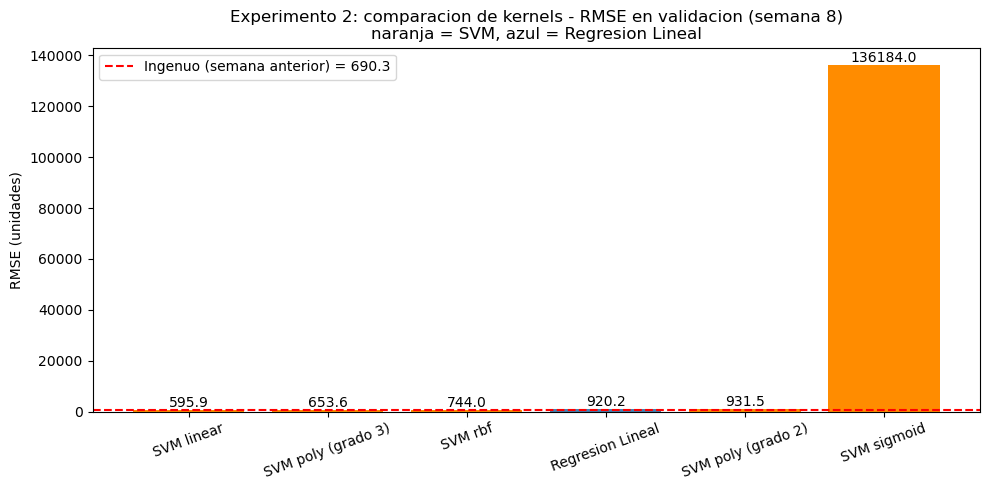

Mejor en esta comparacion: SVM linear (RMSE 595.90)
Peor en esta comparacion:  SVM sigmoid (RMSE 136183.99)


In [22]:
# Grafica del experimento 3 (para las diapositivas y para MLflow)
fig = plt.figure(figsize=(10, 5))
colores = ['steelblue' if m == 'Regresion Lineal' else 'darkorange' for m in tabla_exp2['Modelo']]
plt.bar(tabla_exp2['Modelo'], tabla_exp2['RMSE validacion'], color=colores)
plt.axhline(rmse_ingenuo_val, color='red', linestyle='--', label=f'Ingenuo (semana anterior) = {rmse_ingenuo_val:.1f}')
for i, valor in enumerate(tabla_exp2['RMSE validacion']):
    plt.text(i, valor, f'{valor:.1f}', ha='center', va='bottom')
plt.title('Experimento 2: comparacion de kernels - RMSE en validacion (semana 8)\nnaranja = SVM, azul = Regresion Lineal')
plt.ylabel('RMSE (unidades)')
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.savefig('figuras/svm_exp2_kernels.png', dpi=150)
client.log_figure(RUN_EXP2, fig, 'graficas/exp2_kernels.png')
plt.show()

print(f"Mejor en esta comparacion: {tabla_exp2.iloc[0]['Modelo']} (RMSE {tabla_exp2.iloc[0]['RMSE validacion']:.2f})")
print(f"Peor en esta comparacion:  {tabla_exp2.iloc[-1]['Modelo']} (RMSE {tabla_exp2.iloc[-1]['RMSE validacion']:.2f})")

**Cómo leer este experimento:**

* Las barras más bajas son mejores (menos error). La línea roja es el modelo ingenuo: lo que quede por encima de ella **no sirve**.
* **linear** y la **Regresión Lineal** suelen quedar parecidas: las dos dibujan un hiperplano; la diferencia es que la SVR ignora los errores pequeños (el tubo epsilon) y es menos sensible a valores extremos.
* **poly** permite curvas, pero con grado alto puede sobreajustarse y tarda más en entrenar.
* **rbf con valores por defecto** puede salir mal: depende mucho de **gamma**, y `gamma='scale'` no tiene por qué ser un buen valor para estos datos. Por eso no se descarta todavía: es el que más puede mejorar al ajustarlo (Experimento 3).
* **sigmoid** casi siempre es el peor en regresión: es el kernel que menos se usa en la práctica.

**Qué pasa al Experimento 3 (finetuning):**
* **linear**: normalmente el mejor sin ajustar; vemos si C lo mejora.
* **rbf**: es el kernel más flexible y el que más depende de C y gamma, así que es el que más puede ganar con el ajuste.
* **Se descartan** sigmoid y poly grado 2. Poly grado 3 tampoco pasa: es el más lento (más de 2 minutos por prueba con C = 1, y más con C alto), y lo que ofrece (curvas) ya lo cubre el rbf.

## 3.4 Experimento 3: finetuning de hiperparámetros con `GridSearchCV`

Con la mejor ventana y el mejor grupo de variables (Experimento 1) ajustamos a fondo los dos kernels que pasaron el Experimento 2, igual que en la práctica de clase:
* **linear** con C = 0.1, 1 y 10 (3 configuraciones; gamma no se usa en este kernel).
* **rbf** con C = 0.1, 1 y 10 × gamma = `scale`, 0.1 y 1 (9 configuraciones).

**¿Cómo usamos `GridSearchCV` sin romper el orden del tiempo?** La validación cruzada normal mezcla los ejemplos al azar, y aquí no podemos validar con semanas anteriores a las de entrenamiento. La solución es `PredefinedSplit`: le decimos a mano qué filas son de entrenamiento (`-1`) y cuáles de validación (`0`). Así `GridSearchCV` hace **un solo corte**: entrena con las semanas de entrenamiento y valida con la semana 8, exactamente lo mismo que el recorrido a mano de la versión anterior, pero con dos ventajas:
* `n_jobs=-1` entrena varias combinaciones a la vez (usa todos los núcleos del procesador).
* El *scorer* es nuestro RMSE en unidades reales (`make_scorer`). scikit-learn siempre **maximiza** el score, por eso se pone `greater_is_better=False` y el RMSE aparece con signo negativo.

**Lo del profesor: guardar todas las combinaciones, no solo la última/mejor.** `GridSearchCV` guarda los resultados de las 12 combinaciones en `cv_results_`. Recorremos esa tabla y creamos **un run hijo por combinación** (es lo mismo que hace `mlflow.sklearn.autolog()` con los GridSearch, pero a mano para controlar los nombres). Además guardamos `cv_results_` completo como CSV en el run padre.

`refit=False`: no reentrenamos aquí al ganador porque el modelo final se entrena después, sumando la semana 8.

In [23]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import make_scorer

# Mismos datos que el recorrido a mano: muestra de entrenamiento + TODA la semana 8 como validacion
train_X, train_y = ventanas_svm(datos_esc, semanas_entrenamiento(MEJOR_N_SEM), MEJOR_N_SEM, MEJORES_VARS)
train_X, train_y = muestra(train_X, train_y, N_MUESTRA)
val_X, val_y = ventanas_svm(datos_esc, [SEMANA_VAL], MEJOR_N_SEM, MEJORES_VARS)

X_grid = np.vstack([train_X, val_X])
y_grid = np.concatenate([train_y, val_y])
# -1 = solo entrenamiento, 0 = fold de validacion  ->  un unico corte: entrena semanas 4-7, valida semana 8
corte = PredefinedSplit(np.r_[np.full(len(train_X), -1), np.zeros(len(val_X))])

param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': ['scale', 0.1, 1]},
]
scorer_rmse = make_scorer(rmse_unidades, greater_is_better=False)  # RMSE en unidades reales

grid = GridSearchCV(crear_modelo(), param_grid, cv=corte, scoring=scorer_rmse,
                    refit=False, n_jobs=-1, verbose=1)
grid.fit(X_grid, y_grid)

# cv_results_ tiene UNA fila por combinacion (las 12), no solo la mejor
cv = pd.DataFrame(grid.cv_results_)
cv['rmse_val'] = -cv['mean_test_score']  # quitamos el signo negativo
print(f"Combinaciones evaluadas: {len(cv)}")

Fitting 1 folds for each of 12 candidates, totalling 12 fits
Combinaciones evaluadas: 12


In [24]:
# Registramos en MLflow TODAS las combinaciones del GridSearch: un run hijo por fila de cv_results_
resultados_exp3 = []
with mlflow.start_run(run_name='Exp3_grid_search') as run_padre:
    RUN_EXP3 = run_padre.info.run_id
    mlflow.set_tags({'experimento': 'exp3', 'tipo': 'experimento', 'ejecucion': EJECUCION,
                     'metodo': 'GridSearchCV + PredefinedSplit (valida semana 8)'})
    mlflow.log_params({'ventana': MEJOR_N_SEM, 'n_variables': len(MEJORES_VARS),
                       'n_muestra': N_MUESTRA, 'n_combinaciones': len(cv)})
    mlflow.log_text(json.dumps(param_grid, indent=2), 'grilla/param_grid.json')
    mlflow.log_metric('rmse_ingenuo_val', rmse_ingenuo_val)

    for _, fila in cv.iterrows():
        kernel, C = fila['param_kernel'], float(fila['param_C'])
        gamma = fila['param_gamma'] if kernel == 'rbf' else 'scale'
        nombre = f"exp3_{kernel}_C{C:g}" + (f"_g{gamma}" if kernel == 'rbf' else '')
        with mlflow.start_run(run_name=nombre, nested=True):
            mlflow.set_tags({'experimento': 'exp3', 'tipo': 'prueba', 'ejecucion': EJECUCION})
            mlflow.log_params(params_modelo(MEJOR_N_SEM, MEJORES_VARS, 'SVR', kernel, C, gamma))
            mlflow.log_metric('rmse_val', fila['rmse_val'])
            mlflow.log_metric('mejora_vs_ingenuo_pct', (rmse_ingenuo_val - fila['rmse_val']) / rmse_ingenuo_val * 100)
            mlflow.log_metric('segundos_entrenamiento', fila['mean_fit_time'])
            mlflow.log_metric('ranking_grid', fila['rank_test_score'])
        resultados_exp3.append({'Kernel': kernel, 'C': C, 'Gamma': '-' if kernel == 'linear' else str(gamma),
                                'Segundos': round(fila['mean_fit_time'], 1),
                                'RMSE validacion': round(fila['rmse_val'], 2)})
        print(f"Kernel {kernel} | C {C} | Gamma {gamma} | RMSE validacion: {fila['rmse_val']:.2f}")

    tabla_exp3 = pd.DataFrame(resultados_exp3).sort_values('RMSE validacion').reset_index(drop=True)
    mlflow.log_text(cv.drop(columns=['params']).to_csv(index=False), 'tablas/cv_results_completo.csv')
    mlflow.log_text(tabla_exp3.to_csv(index=False), 'tablas/exp3_resultados.csv')
    mlflow.log_metric('mejor_rmse_val', tabla_exp3['RMSE validacion'].min())

tabla_exp3

Kernel linear | C 0.1 | Gamma scale | RMSE validacion: 596.08
Kernel linear | C 1.0 | Gamma scale | RMSE validacion: 595.90
Kernel linear | C 10.0 | Gamma scale | RMSE validacion: 595.81
Kernel rbf | C 0.1 | Gamma scale | RMSE validacion: 901.57
Kernel rbf | C 0.1 | Gamma 0.1 | RMSE validacion: 587.50
Kernel rbf | C 0.1 | Gamma 1 | RMSE validacion: 645.13
Kernel rbf | C 1.0 | Gamma scale | RMSE validacion: 744.02
Kernel rbf | C 1.0 | Gamma 0.1 | RMSE validacion: 595.61
Kernel rbf | C 1.0 | Gamma 1 | RMSE validacion: 687.60
Kernel rbf | C 10.0 | Gamma scale | RMSE validacion: 897.23
Kernel rbf | C 10.0 | Gamma 0.1 | RMSE validacion: 583.49
Kernel rbf | C 10.0 | Gamma 1 | RMSE validacion: 969.74


,Kernel,C,Gamma,Segundos,RMSE validacion
0,rbf,10.0,0.1,14.6,583.49
1,rbf,0.1,0.1,12.9,587.50
2,rbf,1.0,0.1,13.3,595.61
3,linear,10.0,-,29.3,595.81
4,linear,1.0,-,13.6,595.90
5,linear,0.1,-,10.6,596.08
6,rbf,0.1,1,13.2,645.13
7,rbf,1.0,1,13.8,687.60
8,rbf,1.0,scale,15.0,744.02
9,rbf,10.0,scale,25.0,897.23


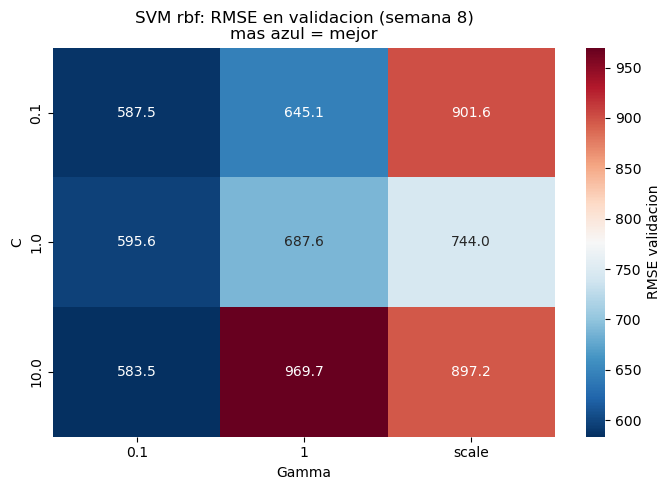

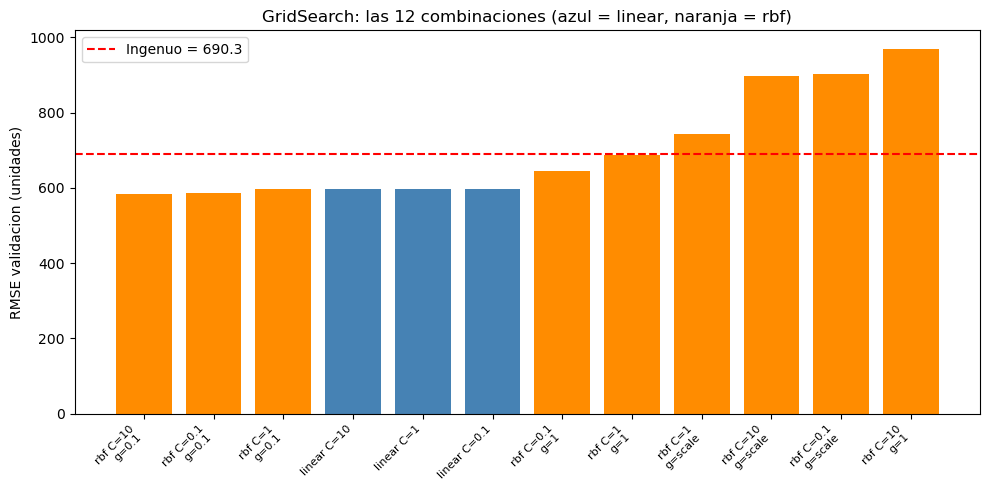

In [25]:
# Heatmap del kernel rbf: RMSE en validacion para cada C y gamma (como en la practica de clase)
tabla_rbf = tabla_exp3[tabla_exp3['Kernel'] == 'rbf']
matriz = tabla_rbf.pivot_table(index='C', columns='Gamma', values='RMSE validacion')

fig = plt.figure(figsize=(7, 5))
sns.heatmap(matriz, annot=True, fmt='.1f', cmap='RdBu_r', cbar_kws={'label': 'RMSE validacion'})
plt.title('SVM rbf: RMSE en validacion (semana 8)\nmas azul = mejor')
plt.tight_layout()
plt.savefig('figuras/svm_heatmap_C_gamma.png', dpi=150)
client.log_figure(RUN_EXP3, fig, 'graficas/heatmap_C_gamma.png')
plt.show()

# Segunda grafica: las 12 combinaciones ordenadas (para ver TODO el grid, no solo el ganador)
fig = plt.figure(figsize=(10, 5))
etiquetas = [f"{r['Kernel']} C={r['C']:g}" + (f"\ng={r['Gamma']}" if r['Kernel'] == 'rbf' else '')
             for _, r in tabla_exp3.iterrows()]
colores = ['steelblue' if k == 'linear' else 'darkorange' for k in tabla_exp3['Kernel']]
plt.bar(etiquetas, tabla_exp3['RMSE validacion'], color=colores)
plt.axhline(rmse_ingenuo_val, color='red', linestyle='--', label=f'Ingenuo = {rmse_ingenuo_val:.1f}')
plt.title('GridSearch: las 12 combinaciones (azul = linear, naranja = rbf)')
plt.ylabel('RMSE validacion (unidades)')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.legend()
plt.tight_layout()
plt.savefig('figuras/svm_grid_todas.png', dpi=150)
client.log_figure(RUN_EXP3, fig, 'graficas/grid_todas_las_combinaciones.png')
plt.show()

In [26]:
# Mejor configuracion del GridSearch (primera fila, porque la tabla esta ordenada)
mejor_conf = tabla_exp3.iloc[0]
MEJOR_KERNEL = mejor_conf['Kernel']
MEJOR_C = float(mejor_conf['C'])
MEJOR_GAMMA = mejor_conf['Gamma']
# gamma se guardo como texto para la tabla: lo regresamos a numero si no es 'scale'
if MEJOR_GAMMA in ['scale', '-']:
    MEJOR_GAMMA = 'scale'
else:
    MEJOR_GAMMA = float(MEJOR_GAMMA)
print(f"Mejor del GridSearch: ventana {MEJOR_N_SEM}, {len(MEJORES_VARS)} variables, "
      f"kernel {MEJOR_KERNEL}, C {MEJOR_C}, gamma {MEJOR_GAMMA}")

Mejor del GridSearch: ventana 1, 5 variables, kernel rbf, C 10.0, gamma 0.1


## 3.5 MLflow elige el mejor resultado entre TODAS las pruebas

Ya no elegimos el ganador mirando una tabla de un solo experimento: le pedimos a MLflow que busque, entre **todas** las pruebas de esta ejecución (4 del Exp1 + 6 del Exp2 + las 12 del GridSearch del Exp3 = 22 pruebas), la que tenga el **menor RMSE de validación**.

`mlflow.search_runs` devuelve una tabla de pandas con una fila por run; con `filter_string` filtramos (solo pruebas, solo esta ejecución) y con `order_by` ordenamos. Es la misma búsqueda que puedes hacer en la interfaz web.

Todas las pruebas se validan con la **misma semana 8 completa**, por eso sus RMSE se pueden comparar entre sí.

Si quieres buscar entre todas las ejecuciones (incluidas las de otros días), pon `SOLO_ESTA_EJECUCION = False`.

In [27]:
SOLO_ESTA_EJECUCION = True

filtro = "tags.tipo = 'prueba'"
if SOLO_ESTA_EJECUCION:
    filtro += f" and tags.ejecucion = '{EJECUCION}'"

todas_las_pruebas = mlflow.search_runs(experiment_names=[NOMBRE_EXPERIMENTO], filter_string=filtro,
                                       order_by=['metrics.rmse_val ASC'])
print(f"Pruebas registradas: {len(todas_las_pruebas)}")

columnas = ['tags.mlflow.runName', 'tags.experimento', 'params.ventana', 'params.n_variables',
            'params.modelo_tipo', 'params.kernel', 'params.C', 'params.gamma', 'metrics.rmse_val']
display(todas_las_pruebas[columnas].head(10))

# La mejor prueba (primera fila) y su configuracion, leida desde MLflow
mejor_run = todas_las_pruebas.iloc[0]
RUN_MEJOR_PRUEBA = mejor_run['run_id']

def a_numero(valor):
    # MLflow guarda los params como texto: '10.0' -> 10.0, 'scale' -> 'scale'
    try:
        return float(valor)
    except (TypeError, ValueError):
        return valor

CONFIG_FINAL = {
    'ventana': int(mejor_run['params.ventana']),
    'variables': VARS_ORIGINALES if int(mejor_run['params.n_variables']) == 5 else VARS_CON_TEMPORALES,
    'modelo_tipo': mejor_run['params.modelo_tipo'],
    'kernel': mejor_run['params.kernel'],
    'C': a_numero(mejor_run['params.C']),
    'gamma': a_numero(mejor_run['params.gamma']),
    'degree': int(a_numero(mejor_run['params.degree'])) if 'params.degree' in mejor_run and pd.notna(mejor_run['params.degree']) else 3,
    'coef0': a_numero(mejor_run['params.coef0']) if 'params.coef0' in mejor_run and pd.notna(mejor_run['params.coef0']) else 0.0,
}
MEJOR_N_SEM = CONFIG_FINAL['ventana']
MEJORES_VARS = CONFIG_FINAL['variables']
print(f"\nMejor prueba: {mejor_run['tags.mlflow.runName']} ({mejor_run['tags.experimento']}) "
      f"| RMSE validacion {mejor_run['metrics.rmse_val']:.2f}")
print("Configuracion para el modelo final:", {k: v for k, v in CONFIG_FINAL.items() if k != 'variables'})

Pruebas registradas: 22


,tags.mlflow.runName,tags.experimento,params.ventana,params.n_variables,params.modelo_tipo,params.kernel,params.C,params.gamma,metrics.rmse_val
0,exp3_rbf_C10_g0.1,exp3,1,5,SVR,rbf,10.0,0.1,583.490053
1,exp3_rbf_C0.1_g0.1,exp3,1,5,SVR,rbf,0.1,0.1,587.503682
2,exp3_rbf_C1_g0.1,exp3,1,5,SVR,rbf,1.0,0.1,595.610397
3,exp3_linear_C10,exp3,1,5,SVR,linear,10.0,scale,595.806216
4,exp3_linear_C1,exp3,1,5,SVR,linear,1.0,scale,595.903982
5,exp2_SVM_linear,exp2,1,5,SVR,linear,1.0,scale,595.903982
6,exp1_v1_originales,exp1,1,5,SVR,linear,1.0,scale,595.903982
7,exp3_linear_C0.1,exp3,1,5,SVR,linear,0.1,scale,596.083889
8,exp1_v3_temporales,exp1,3,7,SVR,linear,1.0,scale,629.878402
9,exp1_v1_temporales,exp1,1,7,SVR,linear,1.0,scale,640.038716



Mejor prueba: exp3_rbf_C10_g0.1 (exp3) | RMSE validacion 583.49
Configuracion para el modelo final: {'ventana': 1, 'modelo_tipo': 'SVR', 'kernel': 'rbf', 'C': 10.0, 'gamma': 0.1, 'degree': 3, 'coef0': 0.0}


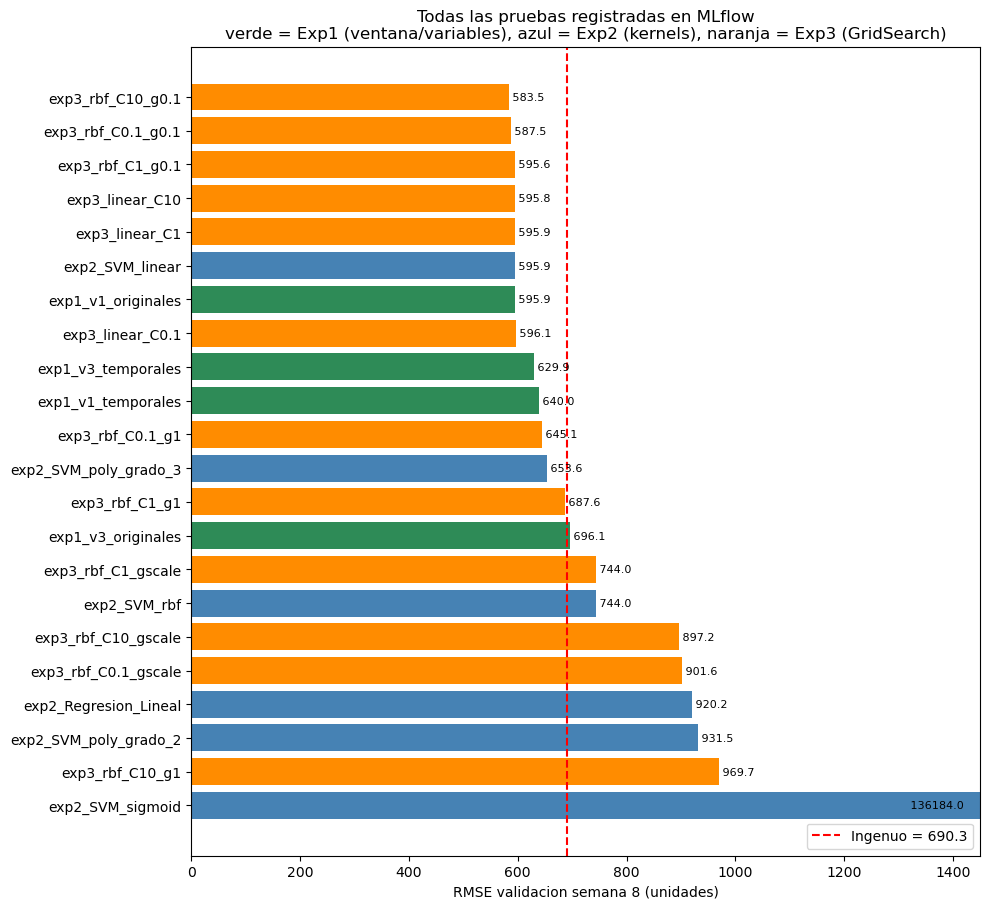

In [28]:
# Grafica de TODAS las pruebas, ordenadas de mejor a peor (recortamos el eje para que sigmoid no aplaste el resto)
ranking = todas_las_pruebas.sort_values('metrics.rmse_val', ascending=False)
colores_exp = {'exp1': 'seagreen', 'exp2': 'steelblue', 'exp3': 'darkorange'}

fig, ax = plt.subplots(figsize=(10, 0.35 * len(ranking) + 1.5))
ax.barh(ranking['tags.mlflow.runName'], ranking['metrics.rmse_val'],
        color=[colores_exp[e] for e in ranking['tags.experimento']])
ax.axvline(rmse_ingenuo_val, color='red', linestyle='--', label=f'Ingenuo = {rmse_ingenuo_val:.1f}')
limite = min(ranking['metrics.rmse_val'].max(), rmse_ingenuo_val * 2) * 1.05
ax.set_xlim(0, limite)
for y, v in enumerate(ranking['metrics.rmse_val']):
    ax.text(min(v, limite * 0.98), y, f' {v:.1f}', va='center', ha='right' if v > limite else 'left', fontsize=8)
ax.set_xlabel('RMSE validacion semana 8 (unidades)')
ax.set_title('Todas las pruebas registradas en MLflow\nverde = Exp1 (ventana/variables), azul = Exp2 (kernels), naranja = Exp3 (GridSearch)')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig('figuras/svm_ranking_todas_las_pruebas.png', dpi=150)
plt.show()
FIG_RANKING = fig  # se guarda en el run del modelo final (siguiente celda)

## 3.6 Modelo final, evaluación en la semana 9 y registro en el Model Registry

Entrenamos el modelo final con la configuración ganadora **sumando la semana 8 al entrenamiento** y con una muestra más grande (`N_MUESTRA_FINAL`). Después lo evaluamos **una sola vez** en la semana 9, con **todas** las series.

**En MLflow** este es un run aparte, `Modelo_final`, que guarda:
* Los parámetros de la configuración ganadora y el `run_id` de la prueba de la que salió.
* Las métricas de la semana 9: RMSE del modelo, del ingenuo, del LSTM, y el % de mejora.
* El modelo, el `scaler` (para poder usar el modelo con datos nuevos hay que escalarlos igual) y las gráficas.
* `registered_model_name=...` lo guarda en el **Model Registry**: cada vez que corras el cuaderno se crea una **versión** nueva (v1, v2, ...). Con el **alias `champion`** marcamos la versión que se usa; en la Parte 4 cargamos el modelo con `models:/SVM_Demanda_Bimbo@champion`.

In [29]:
N_MUESTRA_FINAL = 40_000
RMSE_LSTM = 634.28  # RMSE de la semana 9 del LSTM (Practica_DL_final). Pon None si no lo quieres comparar

def construir_modelo(config):
    if config['modelo_tipo'] == 'LinearRegression':
        return LinearRegression()
    return SVR(kernel=config['kernel'], C=config['C'], gamma=config['gamma'], degree=config['degree'],
               coef0=config['coef0'], epsilon=0.01, cache_size=1000)

# Entrenamiento = semanas de entrenamiento + la semana 8
semanas_finales = semanas_entrenamiento(MEJOR_N_SEM) + [SEMANA_VAL]
train_X, train_y = ventanas_svm(datos_esc, semanas_finales, MEJOR_N_SEM, MEJORES_VARS)
train_X, train_y = muestra(train_X, train_y, N_MUESTRA_FINAL)
test_X, test_y = ventanas_svm(datos_esc, [SEMANA_TEST], MEJOR_N_SEM, MEJORES_VARS)
print(f"Entrena con semanas {semanas_finales}: {train_X.shape} | Prueba con semana {SEMANA_TEST}: {test_X.shape}")

run_final = mlflow.start_run(run_name='Modelo_final')  # se cierra en la celda 3.7, despues de las graficas
RUN_FINAL = run_final.info.run_id
mlflow.set_tags({'experimento': 'final', 'tipo': 'final', 'ejecucion': EJECUCION,
                 'origen_run_id': RUN_MEJOR_PRUEBA, 'origen_run_name': mejor_run['tags.mlflow.runName']})
p = params_modelo(MEJOR_N_SEM, MEJORES_VARS, CONFIG_FINAL['modelo_tipo'], CONFIG_FINAL['kernel'],
                  CONFIG_FINAL['C'], CONFIG_FINAL['gamma'], degree=CONFIG_FINAL['degree'],
                  coef0=CONFIG_FINAL['coef0'], n_muestra=N_MUESTRA_FINAL)
p['semanas_entrenamiento'] = ','.join(map(str, semanas_finales))
mlflow.log_params(p)

inicio = time()
modelo_final = construir_modelo(CONFIG_FINAL)
modelo_final.fit(train_X, train_y)
segundos = time() - inicio
mlflow.log_metric('segundos_entrenamiento', segundos)
if hasattr(modelo_final, 'support_'):
    mlflow.log_metric('n_vectores_soporte', len(modelo_final.support_))
    print(f"Entrenamiento listo en {segundos:.1f} s | vectores de soporte: {len(modelo_final.support_)}")

Entrena con semanas [4, 5, 6, 7, 8]: (40000, 5) | Prueba con semana 9: (53714, 5)
Entrenamiento listo en 38.3 s | vectores de soporte: 23264


RMSE SVM: 584.33
RMSE ingenuo (semana anterior): 650.30
La SVM reduce el error en 10.1%
RMSE LSTM: 634.28


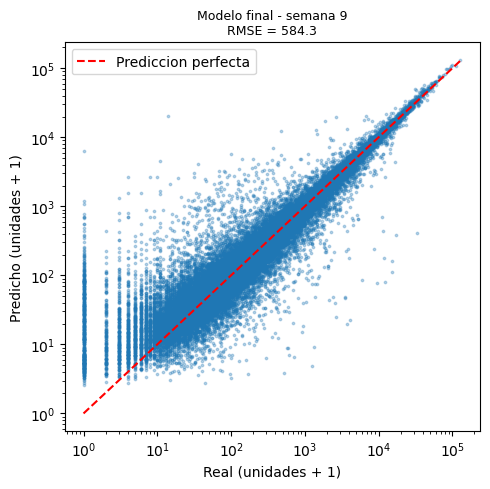

In [30]:
# Para el ingenuo necesitamos la demanda de la semana anterior (la semana 8), en la escala 0-1
test_X_3d, _ = ventanas(datos_esc, [SEMANA_TEST], 1)

y_real = a_unidades(test_y)
y_pred = a_unidades(modelo_final.predict(test_X))
y_base = a_unidades(test_X_3d[:, -1, DEM])  # modelo ingenuo: repetir la semana anterior

rmse_svm = sqrt(mean_squared_error(y_real, y_pred))
rmse_base = sqrt(mean_squared_error(y_real, y_base))
mejora = (rmse_base - rmse_svm) / rmse_base * 100

print(f"RMSE SVM: {rmse_svm:.2f}")
print(f"RMSE ingenuo (semana anterior): {rmse_base:.2f}")
print(f"La SVM reduce el error en {mejora:.1f}%")

mlflow.log_metrics({'rmse_test': rmse_svm, 'mae_test': mean_absolute_error(y_real, y_pred),
                    'rmse_ingenuo_test': rmse_base, 'mejora_vs_ingenuo_pct': mejora,
                    'rmse_val_de_la_prueba_origen': mejor_run['metrics.rmse_val']})
if RMSE_LSTM is not None:
    print(f"RMSE LSTM: {RMSE_LSTM:.2f}")
    mlflow.log_metrics({'rmse_lstm_test': RMSE_LSTM, 'mejora_vs_lstm_pct': (RMSE_LSTM - rmse_svm) / RMSE_LSTM * 100})

fig = grafica_real_vs_pred(y_real, y_pred, f'Modelo final - semana 9\nRMSE = {rmse_svm:.1f}')
mlflow.log_figure(fig, 'graficas/real_vs_predicho_semana9.png')
plt.show()

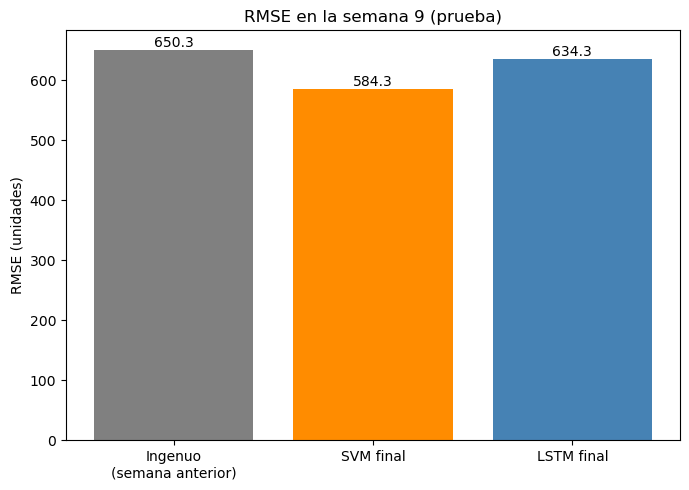

In [31]:
# Grafica: RMSE en la semana 9 (para las diapositivas y para MLflow)
nombres_barras = ['Ingenuo\n(semana anterior)', 'SVM final']
valores = [rmse_base, rmse_svm]
colores = ['gray', 'darkorange']
if RMSE_LSTM is not None:
    nombres_barras.append('LSTM final')
    valores.append(RMSE_LSTM)
    colores.append('steelblue')

fig = plt.figure(figsize=(7, 5))
barras = plt.bar(nombres_barras, valores, color=colores)
for barra, valor in zip(barras, valores):
    plt.text(barra.get_x() + barra.get_width() / 2, valor, f'{valor:.1f}', ha='center', va='bottom')
plt.title('RMSE en la semana 9 (prueba)')
plt.ylabel('RMSE (unidades)')
plt.tight_layout()
plt.savefig('figuras/svm_rmse_final.png', dpi=150)
mlflow.log_figure(fig, 'graficas/rmse_final_semana9.png')
mlflow.log_figure(FIG_RANKING, 'graficas/ranking_todas_las_pruebas.png')
plt.show()

## 3.6 Ejemplos: real vs. predicho y pronóstico de la semana 10

Las mismas gráficas que con el LSTM: para 4 series mostramos la demanda real de las semanas 3 a 9, la predicción de la semana 9 (que sí podemos comparar) y el **pronóstico de la semana 10**, que nadie conoce todavía.

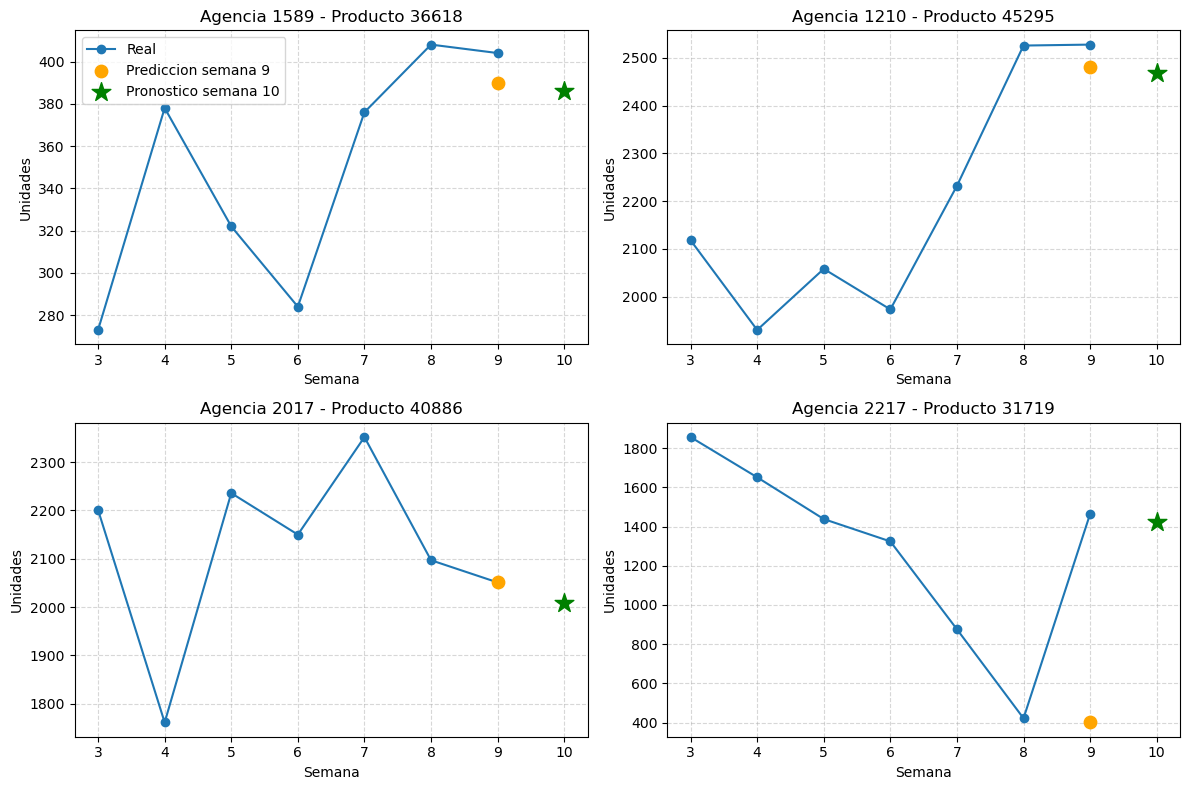

In [32]:
# Elegimos 4 series al azar entre las que venden al menos 100 unidades por semana (para que se vean bien)
grandes = np.where(demanda.mean(axis=1) >= 100)[0]
rng = np.random.default_rng(42)
ejemplos = rng.choice(grandes, size=min(4, len(grandes)), replace=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, i in zip(axes.ravel(), ejemplos):
    # Prediccion de la semana 9 (entrada: semanas anteriores a la 9), aplanada en una fila para la SVM
    X9 = datos_esc[i, 6 - MEJOR_N_SEM:6, :][:, MEJORES_VARS].reshape(1, -1)
    pred9 = a_unidades(modelo_final.predict(X9))[0]
    # Pronostico de la semana 10 (entrada: semanas anteriores a la 10, incluida la 9)
    X10 = datos_esc[i, 7 - MEJOR_N_SEM:7, :][:, MEJORES_VARS].reshape(1, -1)
    pred10 = a_unidades(modelo_final.predict(X10))[0]

    ax.plot(semanas, demanda[i], marker='o', label='Real')
    ax.scatter([9], [pred9], color='orange', s=80, zorder=3, label='Prediccion semana 9')
    ax.scatter([10], [pred10], color='green', marker='*', s=200, zorder=3, label='Pronostico semana 10')
    ax.set_title(f"Agencia {wide.index[i][0]} - Producto {wide.index[i][1]}")
    ax.set_xlabel('Semana')
    ax.set_ylabel('Unidades')
    ax.grid(linestyle='--', alpha=0.5)
axes.ravel()[0].legend()
plt.tight_layout()
plt.savefig('figuras/svm_ejemplos_prediccion.png', dpi=150)
mlflow.log_figure(fig, 'graficas/ejemplos_prediccion.png')
plt.show()

## 3.7 Guardar el modelo final y registrarlo

Guardamos el modelo, el `scaler` y la configuración en el run `Modelo_final`, lo registramos en el **Model Registry** y le ponemos el alias `champion`. Después cerramos el run.

In [33]:
# Modelo + registro en el Model Registry (crea una version nueva cada vez que se ejecuta)
info = mlflow.sklearn.log_model(modelo_final, name='modelo', input_example=test_X[:5],
                                registered_model_name=NOMBRE_MODELO_REGISTRO)

# El scaler y la configuracion: sin ellos no se pueden preparar datos nuevos igual que en el entrenamiento
joblib.dump(scaler, 'scaler.pkl')
mlflow.log_artifact('scaler.pkl', artifact_path='preprocesamiento')
mlflow.log_dict({'ventana': MEJOR_N_SEM, 'variables': [nombres_variables[v] for v in MEJORES_VARS],
                 'indice_variables': MEJORES_VARS, 'transformacion': 'log1p + MinMaxScaler(0,1)',
                 'columna_objetivo': 'Demanda_uni_equil'}, 'preprocesamiento/config.json')
mlflow.end_run()

# Alias 'champion' para la version recien creada
version = info.registered_model_version
client.set_registered_model_alias(NOMBRE_MODELO_REGISTRO, 'champion', version)
client.update_model_version(NOMBRE_MODELO_REGISTRO, version,
                            description=f"{CONFIG_FINAL['kernel']} C={CONFIG_FINAL['C']} gamma={CONFIG_FINAL['gamma']} "
                                        f"| ventana {MEJOR_N_SEM} | RMSE semana 9 = {rmse_svm:.2f} | ejecucion {EJECUCION}")
print(f"Modelo registrado: {NOMBRE_MODELO_REGISTRO} version {version} (alias 'champion')")

Modelo registrado: SVM_Demanda_Bimbo version 1 (alias 'champion')


Successfully registered model 'SVM_Demanda_Bimbo'.
Created version '1' of model 'SVM_Demanda_Bimbo'.


## 3.8 Resumen de la ejecución desde MLflow

Una tabla con los runs padre y el final de esta ejecución, leída directamente de MLflow. Lo mismo se ve en la interfaz web (`mlflow ui`), donde además puedes:
* Seleccionar varios runs y pulsar **Compare** para ver sus parámetros y métricas lado a lado, con gráficas de **coordenadas paralelas** (cómo C y gamma afectan el RMSE) y de dispersión.
* En la pestaña **Chart** del experimento, ver barras del `rmse_val` de todos los runs.
* Entrar a cualquier run y en **Artifacts** ver sus gráficas, tablas y el modelo.
* En **Models** ver las versiones de `SVM_Demanda_Bimbo` y cuál tiene el alias `champion`.

In [34]:
resumen = mlflow.search_runs(experiment_names=[NOMBRE_EXPERIMENTO],
                             filter_string=f"tags.ejecucion = '{EJECUCION}' and tags.tipo != 'prueba'",
                             order_by=['start_time ASC'])
resumen[['tags.mlflow.runName', 'metrics.mejor_rmse_val', 'metrics.rmse_test',
         'metrics.rmse_ingenuo_test', 'metrics.mejora_vs_ingenuo_pct']]

,tags.mlflow.runName,metrics.mejor_rmse_val,metrics.rmse_test,metrics.rmse_ingenuo_test,metrics.mejora_vs_ingenuo_pct
0,Exp1_ventana_y_variables,595.90,NaN,NaN,NaN
1,Exp2_kernels,595.90,NaN,NaN,NaN
2,Exp3_grid_search,583.49,NaN,NaN,NaN
3,Modelo_final,NaN,584.334319,650.301964,10.144156


# Parte 4. Funciones de predicción

**Dataset usado: completo, agregado.** Son las mismas funciones de la práctica del LSTM, pero usando la SVM. Como no hay fechas, se recibe el **número de semana**: de la 4 a la 9 (semanas conocidas, para comparar) o la **10** (pronóstico a futuro).

* `prediccion(agencia, producto, semana)`: demanda de un producto en una agencia.
* `prediccion_producto(producto, semana)`: demanda total de un producto (suma de todas sus agencias).
* `prediccion_lote(lista_productos, semana)`: lo mismo para varios productos a la vez.

Primero cargamos el modelo **desde el Model Registry** con el alias `champion`. Así comprobamos que lo que quedó guardado en MLflow es exactamente el modelo que evaluamos (las predicciones deben ser iguales). En otro cuaderno, o en otra computadora con acceso a `mlflow.db` y `mlruns/`, bastaría esta línea para usar el modelo sin reentrenarlo.

In [35]:
modelo_registrado = mlflow.sklearn.load_model(f"models:/{NOMBRE_MODELO_REGISTRO}@champion")
print("Mismas predicciones que el modelo en memoria:",
      np.allclose(modelo_registrado.predict(test_X[:1000]), modelo_final.predict(test_X[:1000])))
modelo_final = modelo_registrado  # las funciones de abajo usan el modelo cargado desde MLflow

Mismas predicciones que el modelo en memoria: True


In [36]:
idx = {par: i for i, par in enumerate(wide.index)}  # (Agencia_ID, Producto_ID) -> posicion

def prediccion(agencia, producto, semana):
    # Predice la demanda de 'semana' con las semanas anteriores (ventana y variables del modelo elegido)
    i = idx[(agencia, producto)]
    j = semana - 3
    X = datos_esc[i, j-MEJOR_N_SEM:j, :][:, MEJORES_VARS].reshape(1, -1)  # una fila para la SVM
    return float(a_unidades(modelo_final.predict(X))[0])

# Demo: 5 series, semana 9 (la real la conocemos)
for (ag, pr) in list(idx)[:5]:
    real = np.expm1(datos[idx[(ag, pr)], 6, DEM])
    print(f"Agencia {ag} | Producto {pr} | real: {real:.0f} | predicción: {prediccion(ag, pr, 9):.0f}")

Agencia 1110 | Producto 73 | real: 36 | predicción: 37
Agencia 1110 | Producto 108 | real: 688 | predicción: 714
Agencia 1110 | Producto 145 | real: 685 | predicción: 575
Agencia 1110 | Producto 202 | real: 676 | predicción: 635
Agencia 1110 | Producto 205 | real: 141 | predicción: 116


In [37]:
def prediccion_producto(producto, semana):
    # Posiciones de todas las series (agencias) que tienen este producto
    filas = [i for (ag, pr), i in idx.items() if pr == producto]
    if len(filas) == 0:
        return None  # el producto no tiene series con las 7 semanas completas
    j = semana - 3
    X = datos_esc[filas, j-MEJOR_N_SEM:j, :][:, :, MEJORES_VARS].reshape(len(filas), -1)
    pred = a_unidades(modelo_final.predict(X))
    return float(pred.sum())  # demanda total del producto en todas sus agencias

def prediccion_lote(lista_productos, semana):
    # Recibe varios productos y devuelve una prediccion por producto, en el mismo orden
    return [prediccion_producto(p, semana) for p in lista_productos]

In [38]:
# Demo: los 5 productos con mas demanda. Semana 9 (comparamos con lo real) y semana 10 (pronostico)
nombres = productos.drop_duplicates('Producto_ID').set_index('Producto_ID')['NombreProducto']
total_por_producto = wide['Demanda_uni_equil'].groupby(level='Producto_ID').sum().sum(axis=1)
productos_demo = total_por_producto.sort_values(ascending=False).head(5).index.tolist()
pred_9 = prediccion_lote(productos_demo, 9)
pred_10 = prediccion_lote(productos_demo, 10)

filas_resumen = []
for p, p9, p10 in zip(productos_demo, pred_9, pred_10):
    filas = [i for (ag, pr), i in idx.items() if pr == p]
    real_9 = np.expm1(datos[filas, 6, DEM]).sum()
    filas_resumen.append({'Producto': nombres[p], 'Real semana 9': round(real_9),
                          'Prediccion semana 9': round(p9), 'Pronostico semana 10': round(p10)})

pd.DataFrame(filas_resumen)

,Producto,Real semana 9,Prediccion semana 9,Pronostico semana 10
0,Nito 1p 62g Central BIM 2425,2744413,3028238,2633380
1,Nito 1p 62g BIM 1278,2595837,2835664,2536784
2,Rebanada 2p 55g BIM 1284,2299468,2664937,2276946
3,Gansito 1p 50g MTB MLA 43285,2073255,2026981,2030740
4,Bolsa Mini Rocko 40p 13g CU MLA 36610,1889011,1910767,1968157


# Resumen de resultados (para las diapositivas)

Esta celda imprime todos los números de esta ejecución en un solo lugar.

In [39]:
print(f"Series Agencia x Producto: {len(wide)}")
print(f"Ejemplos de entrenamiento: {N_MUESTRA} en los experimentos, {N_MUESTRA_FINAL} en el modelo final")
print(f"Ingenuo en validacion (semana 8): {rmse_ingenuo_val:.2f}")
print()
print("Experimento 1 - ventana y variables, kernel linear (validacion, semana 8):")
print(tabla_exp1.to_string(index=False))
print()
print("Experimento 2 - comparacion rapida de kernels sin ajustar (validacion, semana 8):")
print(tabla_exp2.to_string(index=False))
print()
print("Experimento 3 - finetuning con GridSearch (validacion, semana 8):")
print(tabla_exp3.to_string(index=False))
print()
print(f"Mejor de las {len(todas_las_pruebas)} pruebas (elegido por MLflow): {mejor_run['tags.mlflow.runName']} "
      f"| RMSE validacion {mejor_run['metrics.rmse_val']:.2f}")
print(f"Modelo final: ventana {MEJOR_N_SEM}, {len(MEJORES_VARS)} variables, kernel {CONFIG_FINAL['kernel']}, "
      f"C {CONFIG_FINAL['C']}, gamma {CONFIG_FINAL['gamma']}")
print(f"Prueba (semana 9): RMSE SVM = {rmse_svm:.2f} | RMSE ingenuo = {rmse_base:.2f} | mejora = {mejora:.1f}%")
if RMSE_LSTM is not None:
    print(f"Prueba (semana 9): RMSE LSTM = {RMSE_LSTM:.2f}")

Series Agencia x Producto: 53714
Ejemplos de entrenamiento: 20000 en los experimentos, 40000 en el modelo final
Ingenuo en validacion (semana 8): 690.28

Experimento 1 - ventana y variables, kernel linear (validacion, semana 8):
 Ventana          Variables  Vectores de soporte  Segundos  RMSE validacion
       1     Originales (5)                11891       7.7           595.90
       1 Con temporales (7)                11702       8.3           640.04
       3     Originales (5)                11561      10.7           696.12
       3 Con temporales (7)                11476      13.9           629.88

Experimento 2 - comparacion rapida de kernels sin ajustar (validacion, semana 8):
            Modelo  Segundos  RMSE validacion
        SVM linear       7.6           595.90
SVM poly (grado 3)     124.9           653.58
           SVM rbf      10.2           744.02
  Regresion Lineal       0.0           920.21
SVM poly (grado 2)      38.2           931.47
       SVM sigmoid      15.3    

# Conclusiones

*(Escribir con los números de la celda anterior.)*

* **Experimento 1 (ventana y variables, kernel linear):** la mejor combinación fue ______ con RMSE ______.
* **Experimento 2 (kernels sin ajustar):** el mejor fue ______; sigmoid fue el peor. El rbf sin ajustar sacó ______.
* **Experimento 3 (finetuning):** el ganador fue ______ (C = ___, gamma = ___) con RMSE de validación ______.
* **Modelo final (semana 9):** RMSE ______ frente a ______ del ingenuo (____ % menos error) y 634.28 del LSTM.

Con MLflow, las 22 pruebas (4 del Experimento 1, 6 del Experimento 2 y las 12 combinaciones del GridSearch del Experimento 3) quedan guardadas con sus parámetros, métricas y gráficas, y el modelo final está en el Model Registry como `SVM_Demanda_Bimbo@champion`. Si se vuelve a correr el cuaderno, los resultados anteriores no se pierden: se agregan como nuevos runs y una nueva versión del modelo.